<a href="https://colab.research.google.com/github/galpaillard/meuprojeto/blob/master/Algoritmo_de_Remanejamento_de_Vagas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [Ordem entre as modalidades e Critérios de Remanejamento - HU](https://drive.google.com/drive/u/2/folders/1ZqkIyXesoKOEqsvuKhy8u8KdTGwfaKeK)

- Define a ordem de classificação de cada modalidade em cada uma das inscrições em modalidades, qual seja:
  - AC $\geq$ LI_EP $\geq$ LI_PCD $\geq$ LI_Q $\geq$ LI_I $\geq$ LI_PP $\geq$  LI_PPI $\geq$ LB_EP $\geq$ LB_PCD $\geq$ LB_Q $\geq$ LB_I $\geq$ LB_PP $\geq$ LB_PPI $\geq$ V
- Define a ordem de classificação de cada modalidade considerando as opções de cursos em cada uma das inscrições em modalidades, qual seja:
  -  (1,AC) $\geq$ (1,LI_EP) $\geq$ (1,LI_PCD) $\geq$ (1,LI_Q) $\geq$ (1,LI_I) $\geq$ (1,LI_PP) $\geq$ (1,LI_PPI) $\geq$ (1,LB_EP) $\geq$ (1,LB_PCD) $\geq$ (1,LB_Q) $\geq$ (1,LB_I) $\geq$ (1,LB_PP) $\geq$ (1,LB_PPI) $\geq$ (1,V) $\geq$ (2,AC) $\geq$ (2,LI_EP) $\geq$ (2,LI_PCD) $\geq$ (2,LI_Q) $\geq$ (1,LB_I) $\geq$ (1,LB_PP) $\geq$ (2,LI_PPI) $\geq$ (2,LB_EP) $\geq$ (2,LB_PCD) $\geq$ (2,LB_Q) $\geq$ (2,LB_I) $\geq$ (2,LB_PP) $\geq$ (2,LB_PPI) $\geq$ (2,V)


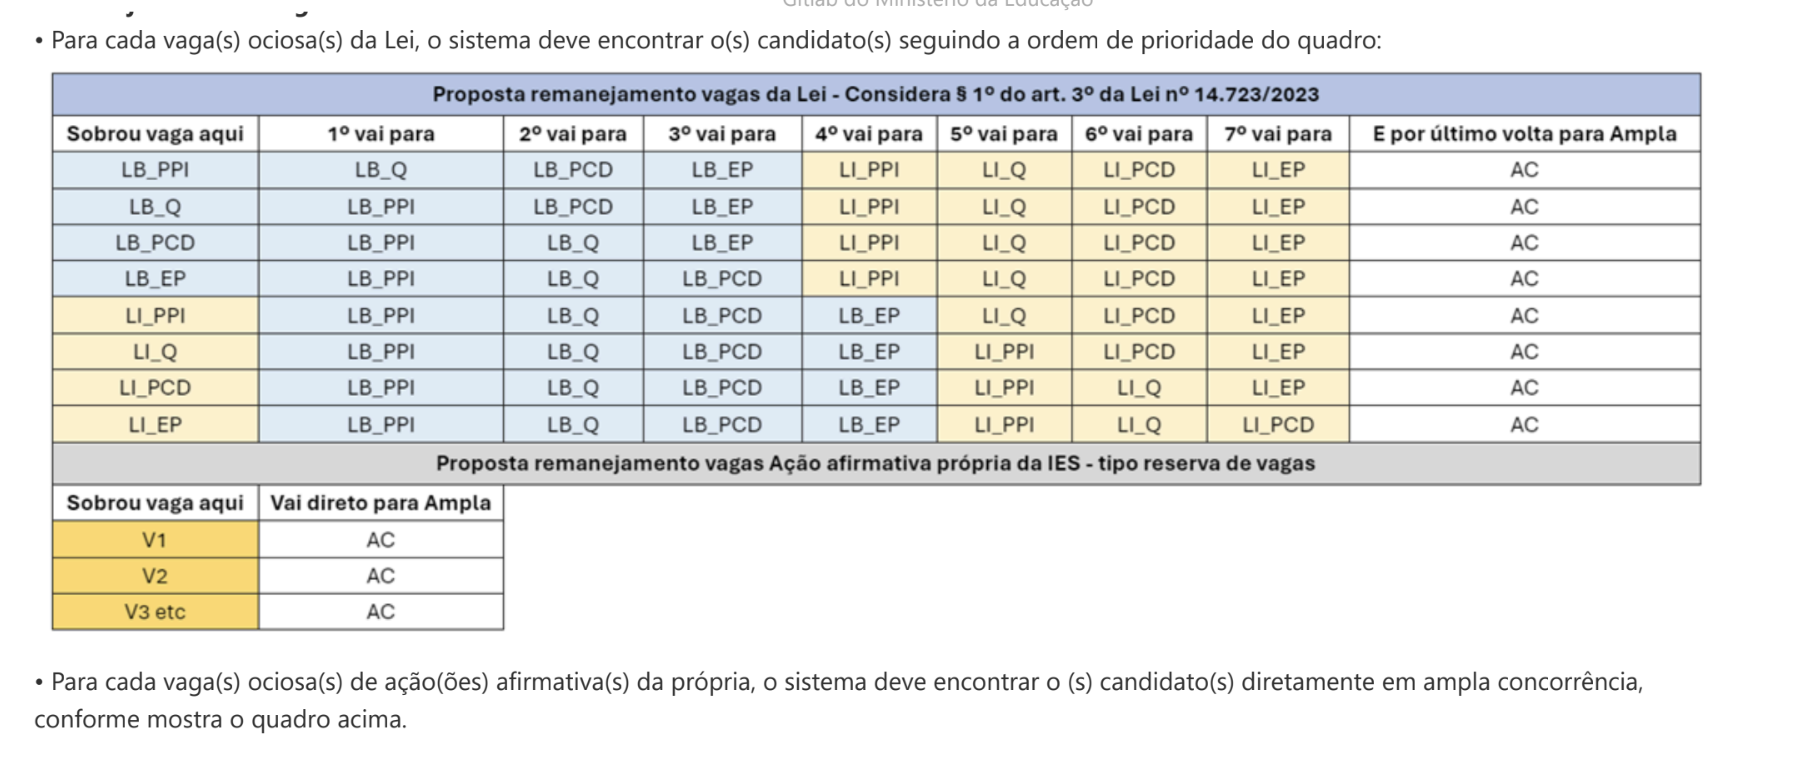

# Sequência de ocupação MEC do remanejamento
Todas as vagas remanescentes serão remanejadas seguindo a seguinte ordem:

1. LB_PPI $\geq$ LB_PP $\geq$ LB_I $\geq$  LB_Q $\geq$ LB_PCD $\geq$ LB_EP $\geq$ LI_PPI $\geq$ LI_PP $\geq$ LI_I $\geq$ LI_Q $\geq$ LI_PCD $\geq$ AC
2. V $\geq$ AC

# Cenário 1

In [ ]:
#@title Exemplo

import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1,2],
  'MODALIDADE':['AC','LB_PCD','LB_PPI','V', 'AC'],
  'QT_VAGAS_OFERTADAS':[3,1,1,1,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LB_PPI,1,1,710,710,710,710,710,710,1,16,16
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20
8,Marcos,LB_PPI,1,1,650,650,650,650,650,650,1,16,16
9,Carla,AC,2,1,640,640,640,640,640,640,1,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PCD,1,2
2,1,LB_PPI,1,5
3,1,V,1,1
4,2,AC,1,1


In [ ]:
#@title Algoritmo de Classificação da Chamada Regular
import pandas as pd

def classificacao_cr(df_concorrencia_cr_serpro,verbose=False):
  # Ordena e classifica os candidatos em cada uma das modalidades
  df_concorrencia_cr_serpro.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
  df_concorrencia_cr_serpro['CLASSIFICACAO']=df_concorrencia_cr_serpro.groupby(by=['ID_CURSO','ORDEM_MODALIDADE']).cumcount()+1
  # Adiciona se aprovado nas vagas em cada lista. Note que um mesmo candidato pode estar aprovado em mais de uma modalidade ou curso
  df_concorrencia_cr_serpro['APROVADO'] = df_concorrencia_cr_serpro['CLASSIFICACAO']<=df_concorrencia_cr_serpro['QT_VAGAS_OFERTADAS']

  # No laço a seguir, retiramos todas as inscrições dos aprovados que estão em ordem lexográfica abaixo da melhor aprovação do candidato
  if verbose:
    print('Algoritmo de classificação')
  while True:
    tam1 = len(df_concorrencia_cr_serpro)

    # Seleciona todos os aprovados
    df_aprovados = df_concorrencia_cr_serpro[(df_concorrencia_cr_serpro['APROVADO']==True)].copy()
    # Ordena todos os aprovados seguindo e a ordenação de aprovado lexográfica
    df_aprovados.sort_values(by=['CO_INSCRICAO_ENEM','ORDEM_MODALIDADE_CURSO'],inplace=True, ascending=[False, False])
    # Salva a melhor classificação do candidato
    df_aprovados_melhor = df_aprovados.groupby(by=['CO_INSCRICAO_ENEM']).first().reset_index()
    df_aprovados_melhor.rename(columns={'ORDEM_MODALIDADE_CURSO':'ORDEM_MODALIDADE_APROVADA'},inplace=True)

    # Para cada candidato aprovado, adiciona a melhor classificação do candidato aprovado
    df_concorrencia_cr_serpro = df_concorrencia_cr_serpro.merge(df_aprovados_melhor[['CO_INSCRICAO_ENEM','ORDEM_MODALIDADE_APROVADA']],how='left',left_on=['CO_INSCRICAO_ENEM'],right_on=['CO_INSCRICAO_ENEM'])

    # Excluir todas as inscrições dos aprovados que estão abaixo da melhor classificação do candidato aprovado
    df_concorrencia_cr_serpro.drop(df_concorrencia_cr_serpro[df_concorrencia_cr_serpro['ORDEM_MODALIDADE_CURSO']<df_concorrencia_cr_serpro['ORDEM_MODALIDADE_APROVADA']].index,inplace=True)
    df_concorrencia_cr_serpro.drop(columns=['ORDEM_MODALIDADE_APROVADA'],inplace=True)

    df_concorrencia_cr_serpro.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
    df_concorrencia_cr_serpro['CLASSIFICACAO']=df_concorrencia_cr_serpro.groupby(by=['ID_CURSO','ORDEM_MODALIDADE']).cumcount()+1
    # Adiciona se aprovado nas vagas em cada lista
    df_concorrencia_cr_serpro['APROVADO'] = df_concorrencia_cr_serpro['CLASSIFICACAO']<=df_concorrencia_cr_serpro['QT_VAGAS_OFERTADAS']
    tam2 = len(df_concorrencia_cr_serpro)

    if verbose:
      print(f"{tam1} - {tam2} = {tam1-tam2}")
    if(tam1==tam2):
      df_cr = df_concorrencia_cr_serpro[df_concorrencia_cr_serpro['APROVADO']==True].copy()
      df_cr.rename(columns={'MODALIDADE_CONCORRENCIA':'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO':'CLASSIFICACAO_CR', 'ST_OPCAO':'ST_OPCAO_CR','APROVADO':'APROVADO_CR'},inplace=True)

      return df_cr

# Define as vagas ocupadas da chamada regular e as remanescentes
def get_vagas_modalidades(df_cr,df_vagas_modalidades,verbose=False):
  df_cr_notacorte_aux = df_cr[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','QT_VAGAS_OFERTADAS','NU_NOTA_INSCRITO','NU_NOTA_R', 'NU_NOTA_L', 'NU_NOTA_M',
        'NU_NOTA_CN', 'NU_NOTA_CH']].groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_CR']).nth(-1)

  df_cr_notacorte_aux.rename(columns={'CLASSIFICACAO_CR':'VAGAS_OCUPADAS_CR',
                                  'NU_NOTA_INSCRITO':'NOTA_CR', 'NU_NOTA_R':'NOTA_R_CR',
                                  'NU_NOTA_L':'NOTA_L_CR', 'NU_NOTA_M':'NOTA_M_CR','NU_NOTA_CN':'NOTA_CN_CR',
                                  'NU_NOTA_CH':'NOTA_CH_CR'},inplace=True)

  # Se todas as vagas não forem preenchidas, define os valores das notas de corte como 0
  df_cr_notacorte_aux.loc[df_cr_notacorte_aux['VAGAS_OCUPADAS_CR']<df_cr_notacorte_aux['QT_VAGAS_OFERTADAS'], ['NOTA_CR','NOTA_R_CR','NOTA_L_CR','NOTA_M_CR', 'NOTA_CN_CR' ,'NOTA_CH_CR']]=0

  df_cr_notacorte_aux['VAGAS_OCUPADAS_CR'] = df_cr_notacorte_aux['VAGAS_OCUPADAS_CR'].astype(int)
  df_cr_notacorte_aux['VAGAS_REMANESCENTES_CR'] = df_cr_notacorte_aux['QT_VAGAS_OFERTADAS']- df_cr_notacorte_aux['VAGAS_OCUPADAS_CR']
  df_cr_notacorte_aux.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
  df_vagas_modalidades_aux = df_vagas_modalidades.merge(df_cr_notacorte_aux, how='left',
                                                    left_on=['ID_CURSO', 'MODALIDADE'],
                                                    right_on=['ID_CURSO',	'MODALIDADE_OCUPADA_CR'])
  df_vagas_modalidades_aux.fillna(0,inplace=True)
  df_vagas_modalidades_aux['VAGAS_OCUPADAS_CR'] = df_vagas_modalidades_aux['VAGAS_OCUPADAS_CR'].astype(int)
  df_vagas_modalidades_aux['VAGAS_REMANESCENTES_CR'] = df_vagas_modalidades_aux['QT_VAGAS_OFERTADAS']- df_vagas_modalidades_aux['VAGAS_OCUPADAS_CR']
  df_vagas_modalidades_aux.drop(columns=['MODALIDADE_OCUPADA_CR'],inplace=True)
  df_vagas_modalidades_aux = df_vagas_modalidades_aux[['ID_CURSO',#'CO_IES', 'SG_IES', 'CO_IES_CURSO','NO_CURSO','NO_CAMPUS','DS_TURNO',
                                              'MODALIDADE', 'INSCRITOS',
                                              'QT_VAGAS_OFERTADAS','VAGAS_OCUPADAS_CR', 'VAGAS_REMANESCENTES_CR',
                                              'NOTA_CR', 'NOTA_R_CR', 'NOTA_L_CR', 'NOTA_M_CR',
                                              'NOTA_CN_CR','NOTA_CH_CR']]
  if verbose==True:
    print(f"{df_vagas_modalidades_aux['VAGAS_REMANESCENTES_CR'].sum()} Vagas Remanescentes")
  return df_vagas_modalidades_aux


In [ ]:
 #@title Algoritmo de Classificação para vagas remanescentes da Chamada Regular

def classifica_cr_remanescentes(df_concorrencia_cr_remanescentes, df_vagas_modalidades, verbose=False):
  """ Algoritmo de classificação das Vagas Remanescentes da Chamada Regular.
      - Entrada: Dataframe com cada candidato classificado em cada modalidade possível de concorrência na lista da chamada regular que não foi aprovado.
      - Saída: Dataframe com os aprovados em cada modalidade.
  """

  # Algoritmo de classificação para as vagas remanescentes da lista de espera
  df_remanescentes_aprovados = None

  for m in modalidades_remanescentes_ordem:
    if verbose:
      print(f"Remanejamentos de {m}")
    # Define o número de vagas remanescentes para a modalidade em cada curso
    df_vaga_m = df_vagas_modalidades[df_vagas_modalidades['MODALIDADE']==m][['ID_CURSO','VAGAS_REMANESCENTES_CR']]

    cursos_vaga_m = df_vaga_m[df_vaga_m['VAGAS_REMANESCENTES_CR']>0]['ID_CURSO'].unique()
    # Adiciona o número de vagas remanescentes para a modalidade em cada curso na lista de concorrência
    df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes[
        (df_concorrencia_cr_remanescentes['ID_CURSO'].isin(cursos_vaga_m))]

    # Adiciona o número de vagas remanescentes para a modalidade em cada curso na lista de concorrência
    df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes_m.merge(df_vaga_m,how='left',left_on=['ID_CURSO'], right_on=['ID_CURSO'])
    df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['VAGAS_REMANESCENTES_CR']>0]
    # Define a origem da vaga que está sendo remanejada
    df_concorrencia_cr_remanescentes_m['VAGA_REMANEJADA_CR'] = m
    # MUDOU AQUI
    # if 'VAGA_REMANEJADA_CR' not in df_concorrencia_cr_remanescentes_m.columns:
    #   df_concorrencia_cr_remanescentes_m['VAGA_REMANEJADA_CR'] = pd.NA
    # df_concorrencia_cr_remanescentes_m['VAGA_REMANEJADA_CR'] = (
    #   df_concorrencia_cr_remanescentes_m['VAGA_REMANEJADA_CR'].fillna(m)
    # )



    # Define a ordem de precedência das vagas remanejadas de acordo com os critérios definidos pelo MEC
    df_concorrencia_cr_remanescentes_m['ORDEM_MODALIDADE_M']= df_concorrencia_cr_remanescentes_m['MODALIDADE_CONCORRENCIA_REMANESCENTE_CR'].map(remanescentes_ordem[m])

    # Realiza a ordenação dos candidatos das vagas remanescentes e a classificação dos candidatos
    df_concorrencia_cr_remanescentes_m.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE_M','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
    df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']=df_concorrencia_cr_remanescentes_m.groupby(by=['ID_CURSO']).cumcount()+1
    df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR'] = df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']<=df_concorrencia_cr_remanescentes_m['VAGAS_REMANESCENTES_CR']

    while True:
      tam1 = len(df_concorrencia_cr_remanescentes_m)

      # Seleciona todos os aprovados
      df_aprovados = df_concorrencia_cr_remanescentes_m[(df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR']==True)].copy()
      # Ordena todos os aprovados seguindo e a ordenação de aprovado lexográfica
      df_aprovados.sort_values(by=['CO_INSCRICAO_ENEM','ORDEM_MODALIDADE_CURSO'],inplace=True, ascending=[False, False])
      # Salva a melhor classificação do candidato
      df_aprovados_melhor = df_aprovados.groupby(by=['CO_INSCRICAO_ENEM']).first().reset_index()
      df_aprovados_melhor.rename(columns={'ORDEM_MODALIDADE_CURSO':'ORDEM_MODALIDADE_APROVADA'},inplace=True)

      # Para cada candidato aprovado, adiciona a melhor classificação do candidato aprovado
      df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes_m.merge(df_aprovados_melhor[['CO_INSCRICAO_ENEM','ORDEM_MODALIDADE_APROVADA']],how='left',left_on=['CO_INSCRICAO_ENEM'],right_on=['CO_INSCRICAO_ENEM'])

      # Excluir todas as inscrições dos aprovados que estão abaixo da melhor classificação do candidato aprovado
      df_concorrencia_cr_remanescentes_m.drop(df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['ORDEM_MODALIDADE_CURSO']<df_concorrencia_cr_remanescentes_m['ORDEM_MODALIDADE_APROVADA']].index,inplace=True)
      df_concorrencia_cr_remanescentes_m.drop(columns=['ORDEM_MODALIDADE_APROVADA'],inplace=True)

      df_concorrencia_cr_remanescentes_m.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE_M','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
      df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']=df_concorrencia_cr_remanescentes_m.groupby(by=['ID_CURSO']).cumcount()+1
      # Adiciona se aprovado nas vagas em cada lista
      df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR'] = df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']<=df_concorrencia_cr_remanescentes_m['VAGAS_REMANESCENTES_CR']
      df_concorrencia_cr_remanescentes_m_aprovados = df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR']==True][['ID_CURSO', 'CO_INSCRICAO_ENEM', 'MODALIDADE_CONCORRENCIA_REMANESCENTE_CR','VAGA_REMANEJADA_CR','VAGAS_REMANESCENTES_CR','CLASSIFICACAO_REMANESCENTE_CR','ST_OPCAO_REMANESCENTE_CR','NU_NOTA_INSCRITO','NU_NOTA_R', 'NU_NOTA_L', 'NU_NOTA_M',
       'NU_NOTA_CN', 'NU_NOTA_CH','ORDEM_MODALIDADE_CURSO']]
      # df_concorrencia_cr_remanescentes_m_aprovados = df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR']==True][['SG_IES', 'CO_IES', 'NO_CURSO', 'CO_IES_CURSO', 'NO_CAMPUS', 'DS_TURNO', 'ID_CURSO', 'CO_INSCRICAO_ENEM', 'MODALIDADE_CONCORRENCIA_REMANESCENTE_CR','VAGA_REMANEJADA_CR','VAGAS_REMANESCENTES_CR','CLASSIFICACAO_REMANESCENTE_CR','ST_OPCAO_REMANESCENTE_CR','NU_NOTA_INSCRITO','NU_NOTA_R', 'NU_NOTA_L', 'NU_NOTA_M',
      #  'NU_NOTA_CN', 'NU_NOTA_CH']]
      tam2 = len(df_concorrencia_cr_remanescentes_m)

      if verbose:
        print(f"{tam1} - {tam2} = {tam1-tam2}")
      if(tam1==tam2):
        # Salva os aprovados nesta modalidade na lista de aprovados das vagas remanescentes
        df_remanescentes_aprovados = pd.concat([df_remanescentes_aprovados,df_concorrencia_cr_remanescentes_m_aprovados])

        df_concorrencia_cr_remanescentes = df_concorrencia_cr_remanescentes[~df_concorrencia_cr_remanescentes['CO_INSCRICAO_ENEM'].isin(df_concorrencia_cr_remanescentes_m_aprovados['CO_INSCRICAO_ENEM'])].copy()
        break

  df_concorrencia_cr_remanescentes = df_concorrencia_cr_remanescentes[df_concorrencia_cr_remanescentes['MODALIDADE_CONCORRENCIA_REMANESCENTE_CR']=='AC']
  for m in l_afps:
    if verbose:
      print(f"Remanejamentos de {m}")
    # Define o número de vagas remanescentes para a modalidade em cada curso
    df_vaga_m = df_vagas_modalidades[df_vagas_modalidades['MODALIDADE']==m][['ID_CURSO','VAGAS_REMANESCENTES_CR']]

    cursos_vaga_m = df_vaga_m[df_vaga_m['VAGAS_REMANESCENTES_CR']>0]['ID_CURSO'].unique()
    # Adiciona o número de vagas remanescentes para a modalidade em cada curso na lista de concorrência
    # df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes.copy().merge(df_vaga_m,how='left',left_on=['ID_CURSO'], right_on=['ID_CURSO'])
    df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes[
        (df_concorrencia_cr_remanescentes['ID_CURSO'].isin(cursos_vaga_m))&
        (df_concorrencia_cr_remanescentes['MODALIDADE_CONCORRENCIA_REMANESCENTE_CR'].isin([m,'AC']))]

    df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes_m.merge(df_vaga_m,how='left',left_on=['ID_CURSO'], right_on=['ID_CURSO'])
    df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['VAGAS_REMANESCENTES_CR']>0]
    # Define a origem da vaga que está sendo remanejada
    df_concorrencia_cr_remanescentes_m['VAGA_REMANEJADA_CR'] = m
    # Define a ordem de precedência das vagas remanejadas de acordo com os critérios definidos pelo MEC
    df_concorrencia_cr_remanescentes_m['ORDEM_MODALIDADE_M']= df_concorrencia_cr_remanescentes_m['MODALIDADE_CONCORRENCIA_REMANESCENTE_CR'].map(remanescentes_ordem[m])

    # Realiza a ordenação dos candidatos das vagas remanescentes e a classificação dos candidatos
    df_concorrencia_cr_remanescentes_m.sort_values(by=['ID_CURSO','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
    df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']=df_concorrencia_cr_remanescentes_m.groupby(by=['ID_CURSO']).cumcount()+1
    df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR'] = df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']<=df_concorrencia_cr_remanescentes_m['VAGAS_REMANESCENTES_CR']


    while True:
      tam1 = len(df_concorrencia_cr_remanescentes_m)

      # Seleciona todos os aprovados
      df_aprovados = df_concorrencia_cr_remanescentes_m[(df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR']==True)].copy()
      # Ordena todos os aprovados seguindo e a ordenação de aprovado lexográfica
      df_aprovados.sort_values(by=['CO_INSCRICAO_ENEM','ORDEM_MODALIDADE_CURSO'],inplace=True, ascending=[False, False])
      # Salva a melhor classificação do candidato
      df_aprovados_melhor = df_aprovados.groupby(by=['CO_INSCRICAO_ENEM']).first().reset_index()
      df_aprovados_melhor.rename(columns={'ORDEM_MODALIDADE_CURSO':'ORDEM_MODALIDADE_APROVADA'},inplace=True)

      # Para cada candidato aprovado, adiciona a melhor classificação do candidato aprovado
      df_concorrencia_cr_remanescentes_m = df_concorrencia_cr_remanescentes_m.merge(df_aprovados_melhor[['CO_INSCRICAO_ENEM','ORDEM_MODALIDADE_APROVADA']],how='left',left_on=['CO_INSCRICAO_ENEM'],right_on=['CO_INSCRICAO_ENEM'])

      # Excluir todas as inscrições dos aprovados que estão abaixo da melhor classificação do candidato aprovado
      df_concorrencia_cr_remanescentes_m.drop(df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['ORDEM_MODALIDADE_CURSO']<df_concorrencia_cr_remanescentes_m['ORDEM_MODALIDADE_APROVADA']].index,inplace=True)
      df_concorrencia_cr_remanescentes_m.drop(columns=['ORDEM_MODALIDADE_APROVADA'],inplace=True)

      df_concorrencia_cr_remanescentes_m.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE_M','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
      df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']=df_concorrencia_cr_remanescentes_m.groupby(by=['ID_CURSO']).cumcount()+1
      # Adiciona se aprovado nas vagas em cada lista
      df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR'] = df_concorrencia_cr_remanescentes_m['CLASSIFICACAO_REMANESCENTE_CR']<=df_concorrencia_cr_remanescentes_m['VAGAS_REMANESCENTES_CR']
      df_concorrencia_cr_remanescentes_m_aprovados = df_concorrencia_cr_remanescentes_m[df_concorrencia_cr_remanescentes_m['APROVADO_REMANESCENTE_CR']==True][[
           'ID_CURSO', 'CO_INSCRICAO_ENEM', 'MODALIDADE_CONCORRENCIA_REMANESCENTE_CR','VAGA_REMANEJADA_CR','VAGAS_REMANESCENTES_CR','CLASSIFICACAO_REMANESCENTE_CR','ST_OPCAO_REMANESCENTE_CR','NU_NOTA_INSCRITO','NU_NOTA_R', 'NU_NOTA_L', 'NU_NOTA_M',
       'NU_NOTA_CN', 'NU_NOTA_CH','ORDEM_MODALIDADE_CURSO']]
      tam2 = len(df_concorrencia_cr_remanescentes_m)

      if verbose:
        print(f"{tam1} - {tam2} = {tam1-tam2}")
      if(tam1==tam2):
        # Salva os aprovados nesta modalidade na lista de aprovados das vagas remanescentes
        df_remanescentes_aprovados = pd.concat([df_remanescentes_aprovados,df_concorrencia_cr_remanescentes_m_aprovados])

        df_concorrencia_cr_remanescentes = df_concorrencia_cr_remanescentes[~df_concorrencia_cr_remanescentes['CO_INSCRICAO_ENEM'].isin(df_concorrencia_cr_remanescentes_m_aprovados['CO_INSCRICAO_ENEM'])].copy()
        break

  return df_remanescentes_aprovados

In [ ]:
#@title Algoritmo de Classificação da Chamada Regular+Classificação das Vagas Remanescentes (Duas Fases)
import time
import pandas as pd

def get_vagas_modalidades_apos_remanescentes(df_cr_remanescentes, df_vagas_modalidades,verbose=False):
  # Nota de Corte do Curso por Modalidade
  if verbose==True:
    print("Define a nota de corte das vagas remanescentes da chamada regular")
  df_cr_remanescentes.sort_values(by=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
  df_remanescentes_cr_notacorte = df_cr_remanescentes.groupby(by=['ID_CURSO',
                                            'MODALIDADE_OCUPADA_REMANESCENTE_CR']).agg(
                                                VAGAS_OCUPADAS_REMANESCENTE_CR=('CO_INSCRICAO_ENEM','count'),
                                                NOTA_REMANESCENTE_CR=('NU_NOTA_INSCRITO','last'),
                                                NOTA_R_REMANESCENTE_CR=('NU_NOTA_R','last'),
                                                NOTA_L_REMANESCENTE_CR=('NU_NOTA_L','last'),
                                                NOTA_M_REMANESCENTE_CR=('NU_NOTA_M','last'),
                                                NOTA_CN_REMANESCENTE_CR=('NU_NOTA_CN','last'),
                                                NOTA_CH_REMANESCENTE_CR=('NU_NOTA_CH','last')
                                                ).reset_index()

  df_vagas_modalidades = df_vagas_modalidades.merge(df_cr_remanescentes.groupby(by=['ID_CURSO','VAGA_REMANEJADA_CR']).agg(
      VAGAS_REMANEJADAS=('CO_INSCRICAO_ENEM','count')).reset_index(), how='left', left_on=['ID_CURSO', 'MODALIDADE'], right_on=['ID_CURSO','VAGA_REMANEJADA_CR'])

  df_vagas_modalidades = df_vagas_modalidades.merge(df_remanescentes_cr_notacorte, how='left',left_on=['ID_CURSO', 'MODALIDADE'], right_on=['ID_CURSO',	'MODALIDADE_OCUPADA_REMANESCENTE_CR'])
  df_vagas_modalidades.fillna(0,inplace=True)
  df_vagas_modalidades['VAGAS_REMANEJADAS'] = df_vagas_modalidades['VAGAS_REMANEJADAS'].astype(int)
  df_vagas_modalidades['VAGAS_OCUPADAS_REMANESCENTE_CR'] = df_vagas_modalidades['VAGAS_OCUPADAS_REMANESCENTE_CR'].astype(int)
  df_vagas_modalidades.drop(columns=['MODALIDADE_OCUPADA_REMANESCENTE_CR','VAGA_REMANEJADA_CR'],inplace=True)
  df_vagas_modalidades.rename(columns={'QT_VAGAS_OFERTADAS':'QT_VAGAS_OFERTADAS_CR'},inplace=True)
  df_vagas_modalidades['QT_VAGAS_OFERTADAS'] = df_vagas_modalidades['QT_VAGAS_OFERTADAS_CR']+df_vagas_modalidades['VAGAS_OCUPADAS_REMANESCENTE_CR']-df_vagas_modalidades['VAGAS_REMANEJADAS']
  df_vagas_modalidades['VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR'] = df_vagas_modalidades['VAGAS_OCUPADAS_CR']+df_vagas_modalidades['VAGAS_OCUPADAS_REMANESCENTE_CR']
  df_vagas_modalidades = df_vagas_modalidades[['ID_CURSO', 'MODALIDADE', 'INSCRITOS',
                                              'QT_VAGAS_OFERTADAS','VAGAS_REMANEJADAS','QT_VAGAS_OFERTADAS_CR','VAGAS_OCUPADAS_CR', 'VAGAS_REMANESCENTES_CR','VAGAS_OCUPADAS_REMANESCENTE_CR', 'VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR',
                                              'NOTA_CR', 'NOTA_R_CR', 'NOTA_L_CR', 'NOTA_M_CR',
                                              'NOTA_CN_CR','NOTA_CH_CR',
                                              'NOTA_REMANESCENTE_CR', 'NOTA_R_REMANESCENTE_CR', 'NOTA_L_REMANESCENTE_CR', 'NOTA_M_REMANESCENTE_CR',
                                              'NOTA_CN_REMANESCENTE_CR','NOTA_CH_REMANESCENTE_CR']]
  if verbose==True:
    print(f"{df_vagas_modalidades['VAGAS_OCUPADAS_REMANESCENTE_CR'].sum()} Vagas Ocupadas das {df_vagas_modalidades['VAGAS_REMANESCENTES_CR'].sum()} Vagas Remanescentes")

  df_vagas_modalidades['NOTA_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_REMANESCENTE_CR']
  df_vagas_modalidades.loc[df_vagas_modalidades['NOTA_CR_E_REMANESCENTE_CR']==0,'NOTA_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_CR']
  df_vagas_modalidades['NOTA_R_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_R_REMANESCENTE_CR']
  df_vagas_modalidades.loc[df_vagas_modalidades['NOTA_R_CR_E_REMANESCENTE_CR']==0,'NOTA_R_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_R_CR']
  df_vagas_modalidades['NOTA_L_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_L_REMANESCENTE_CR']
  df_vagas_modalidades.loc[df_vagas_modalidades['NOTA_L_CR_E_REMANESCENTE_CR']==0,'NOTA_L_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_L_CR']
  df_vagas_modalidades['NOTA_M_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_M_REMANESCENTE_CR']
  df_vagas_modalidades.loc[df_vagas_modalidades['NOTA_M_CR_E_REMANESCENTE_CR']==0,'NOTA_M_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_M_CR']
  df_vagas_modalidades['NOTA_CN_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_CN_REMANESCENTE_CR']
  df_vagas_modalidades.loc[df_vagas_modalidades['NOTA_CN_CR_E_REMANESCENTE_CR']==0,'NOTA_CN_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_CN_CR']
  df_vagas_modalidades['NOTA_CH_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_CH_REMANESCENTE_CR']
  df_vagas_modalidades.loc[df_vagas_modalidades['NOTA_CH_CR_E_REMANESCENTE_CR']==0,'NOTA_CH_CR_E_REMANESCENTE_CR'] = df_vagas_modalidades['NOTA_CH_CR']

  return df_vagas_modalidades


def classificacao_cr_e_remanescente(df_classificacao_cr, df_vagas_modalidades, verbose=False):
  inicio = time.time()
  df_cr = classificacao_cr(df_classificacao_cr, verbose=verbose)
  # Altera o nome como ocorre nos arquivos do MEC para manter o código semelhante
  # df_cr.rename(columns={'QT_VAGAS_OFERTADAS':'QT_VAGAS_CONCORRENCIA'},inplace=True)
  fim = time.time()
  if verbose==True:
    print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s para Chamada Regular")

  df_vagas_ocupadas_cr = get_vagas_modalidades(df_cr, df_vagas_modalidades,verbose=verbose)


  # Define as listas de concorrência dos não aprovados na lista de espera
  df_concorrencia_cr_remanescentes = df_classificacao_cr[~df_classificacao_cr['CO_INSCRICAO_ENEM'].isin(df_cr['CO_INSCRICAO_ENEM'])].copy()
  df_concorrencia_cr_remanescentes.rename(columns={'ST_OPCAO':'ST_OPCAO_REMANESCENTE_CR','MODALIDADE_CONCORRENCIA':'MODALIDADE_CONCORRENCIA_REMANESCENTE_CR','CLASSIFICACAO':'CLASSIFICACAO_REMANESCENTE_CR'},inplace=True)

  inicio = time.time()
  df_cr_remanescentes = classifica_cr_remanescentes(df_concorrencia_cr_remanescentes,df_vagas_ocupadas_cr, verbose=verbose)
  # df_cr_remanescentes = classifica_cr_remanescentes(df_concorrencia_cr_remanescentes,df_vagas_modalidades, verbose=verbose)
  fim = time.time()
  if verbose==True:
    print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s para as vagas remanescentes da chamada regular")

  df_cr_remanescentes.rename(columns={'MODALIDADE_CONCORRENCIA_REMANESCENTE_CR':'MODALIDADE_OCUPADA_REMANESCENTE_CR'},inplace=True)
  df_cr_remanescentes['APROVADO_REMANESCENTE_CR'] = True

  df_vagas_ocupadas_cr_remanescentes = get_vagas_modalidades_apos_remanescentes(df_cr_remanescentes, df_vagas_ocupadas_cr,verbose=verbose)

  df_cr_resumo = df_cr[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','NU_NOTA_INSCRITO','CO_INSCRICAO_ENEM','ST_OPCAO_CR','ORDEM_MODALIDADE_CURSO']].copy()
  df_cr_resumo['VAGA_REMANEJADA_CR'] = np.nan
  df_cr_resumo.sort_values(by=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],inplace=True)

  df_cr_remanescente_resumo =  df_cr_remanescentes[['ID_CURSO', 'MODALIDADE_OCUPADA_REMANESCENTE_CR',
        'CLASSIFICACAO_REMANESCENTE_CR',
        'NU_NOTA_INSCRITO','CO_INSCRICAO_ENEM','ST_OPCAO_REMANESCENTE_CR', 'VAGA_REMANEJADA_CR','ORDEM_MODALIDADE_CURSO']].copy()
  df_cr_remanescente_resumo.rename(columns={'MODALIDADE_OCUPADA_REMANESCENTE_CR':'MODALIDADE_OCUPADA_CR',
                                            'CLASSIFICACAO_REMANESCENTE_CR':'CLASSIFICACAO_CR',
                                            'ST_OPCAO_REMANESCENTE_CR':'ST_OPCAO_CR'},inplace=True)
  df_cr_remanescente_resumo.sort_values(by=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],inplace=True)

  df_cr_com_remanejamento =pd.concat([df_cr_resumo,df_cr_remanescente_resumo])
  df_cr_com_remanejamento.rename(columns={'CLASSIFICACAO_CR':'CLASSIFICACAO_CR_ORIGINAL'},inplace=True)
  df_cr_com_remanejamento['CLASSIFICACAO_CR'] = df_cr_com_remanejamento.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_CR']).cumcount()+1
  df_cr_com_remanejamento.sort_values(by=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],inplace=True)


  return df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_ocupadas_cr_remanescentes



In [ ]:
# #@title Algoritmo de Classificação da Chamada Regular Iterativo
# pd.set_option('future.no_silent_downcasting', True)
# def classificacao_cr_iterativo(df_concorrencia_cr, df_vagas_modalidades, verbose=False,max_iter=None):
#   i = 1
#   inicio = time.time()
#   # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#   df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr, df_vagas_modalidades, verbose=False)

#   # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#   df_concorrencia_cr_com_vagas_remanejadas.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                             left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                             right_on= ['ID_CURSO','MODALIDADE'])
#   # Classifica os candidatos com as vagas remanejadas
#   df_cr_com_vagas_remanejadas = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(df_cr_com_remanejamento[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#   #
#   # df_vagas_modalidades_com_remanejamento = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

#   df_vagas_modalidades_com_vagas_remanejadas_cr = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#   # Adiciona o rastreio das vagas remanejadas
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(
#       df_cr_com_remanejamento[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#       how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#   df_cr_com_vagas_remanejadas.loc[df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR1']
#   df_cr_com_vagas_remanejadas.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)


#   if verbose:
#     print(f"Aprovados {i}")
#     display(df_cr_com_vagas_remanejadas)

#     print(f"Vagas ocupadas {i}")
#     display(df_vagas_modalidades_com_vagas_remanejadas_cr)

#   while True:
#     if max_iter==i:
#       break
#     # Altera as vagas para executar novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr_com_vagas_remanejadas_2.merge(df_vagas_modalidades_com_vagas_remanejadas_cr[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])

#     # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#     df_cr_2, df_cr_remanescentes_2, df_cr_com_remanejamento_2, df_vagas_modalidades_com_remanejamento_2 = classificacao_cr_e_remanescente(df_concorrencia_cr_com_vagas_remanejadas_2.copy(), df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']].copy(), verbose=False)



#     # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento_2[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE', 'INSCRITOS','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])
#     # Classifica os candidatos com as vagas remanejadas
#     df_cr_com_vagas_remanejadas_2 = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_cr_com_remanejamento_2[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#     #
#     # df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2, df_cr_com_vagas_remanejadas_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']])
#     df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2,df_vagas_modalidades_com_remanejamento_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(
#         df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#         how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#     df_cr_com_vagas_remanejadas_2.loc[df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR1']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)

#     if(df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']].equals(df_vagas_modalidades_com_vagas_remanejadas_cr_2[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']])):
#       break
#     i = i +1
#     if verbose:
#       print(f"Aprovados {i}")
#       display(df_cr_com_vagas_remanejadas_2)

#       print(f"Vagas ocupadas {i}")
#       display(df_vagas_modalidades_com_vagas_remanejadas_cr_2)
#     df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas_2
#     df_vagas_modalidades_com_vagas_remanejadas_cr = df_vagas_modalidades_com_vagas_remanejadas_cr_2

#   fim = time.time()

#   if verbose:
#     print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s")
#   return df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr



In [ ]:
# #@title V2 - Algoritmo de Classificação da Chamada Regular Iterativo
# pd.set_option('future.no_silent_downcasting', True)
# def classificacao_cr_iterativo(df_concorrencia_cr, df_vagas_modalidades, verbose=False,max_iter=None):
#   i = 1
#   inicio = time.time()
#   # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#   df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr, df_vagas_modalidades, verbose=False)

#   # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#   df_concorrencia_cr_com_vagas_remanejadas.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                             left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                             right_on= ['ID_CURSO','MODALIDADE'])
#   # Classifica os candidatos com as vagas remanejadas
#   df_cr_com_vagas_remanejadas = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(df_cr_com_remanejamento[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#   #
#   # df_vagas_modalidades_com_remanejamento = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

#   df_vagas_modalidades_com_vagas_remanejadas_cr = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#   # Adiciona o rastreio das vagas remanejadas
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(
#       df_cr_com_remanejamento[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#       how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#   df_cr_com_vagas_remanejadas.loc[df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR1']
#   df_cr_com_vagas_remanejadas.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)

#   # Adiciona o rastreio das vagas remanejadas que não foram preenchidas. Armazena o rastreio das vagas que foram ocupadas quando da execução da reiteração
#   df_vagas_nao_ocupadas = df_cr_com_remanejamento[[
#       'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']].merge(
#           df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#           how='left',
#           on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#           indicator=True
#       ).query("_merge == 'left_only'").drop(columns="_merge")

#   if verbose:
#     print(f"Aprovados {i}")
#     display(df_cr_com_vagas_remanejadas)

#     print(f"Vagas ocupadas {i}")
#     display(df_vagas_modalidades_com_vagas_remanejadas_cr)

#   while True:
#     if max_iter==i:
#       break
#     # Altera as vagas para executar novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr_com_vagas_remanejadas_2.merge(df_vagas_modalidades_com_vagas_remanejadas_cr[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])

#     # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#     df_cr_2, df_cr_remanescentes_2, df_cr_com_remanejamento_2, df_vagas_modalidades_com_remanejamento_2 = classificacao_cr_e_remanescente(df_concorrencia_cr_com_vagas_remanejadas_2.copy(), df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']].copy(), verbose=False)



#     # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento_2[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE', 'INSCRITOS','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])
#     # Classifica os candidatos com as vagas remanejadas
#     df_cr_com_vagas_remanejadas_2 = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_cr_com_remanejamento_2[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#     #
#     # df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2, df_cr_com_vagas_remanejadas_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']])
#     df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2,df_vagas_modalidades_com_remanejamento_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(
#         df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#         how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#     df_cr_com_vagas_remanejadas_2.loc[df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR1']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)


#     # Para adicionar as vagas que foram agora preenchidas e que não tinham sido ocupadas na iteraçãoa anterior
#     df_vagas_remanejadas_resumo = df_cr_com_vagas_remanejadas_2[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull()][
#         ['MODALIDADE_OCUPADA_CR', 'ID_CURSO',
#           'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR' ]]
#     df_vagas_remanejadas_resumo['ORDEM_MERGE']=df_vagas_remanejadas_resumo.groupby(by=['ID_CURSO','VAGA_REMANEJADA_CR']).cumcount()+1

#     df_vagas_nao_ocupadas['ORDEM_MERGE']= df_vagas_nao_ocupadas.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_CR']).cumcount()+1

#     # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior
#     df_resultado_nao_ocupadas_remanejamento = df_vagas_nao_ocupadas.merge(
#         df_vagas_remanejadas_resumo,
#         how='left',
#         right_on=['ID_CURSO','VAGA_REMANEJADA_CR','ORDEM_MERGE'],
#         left_on=['ID_CURSO','MODALIDADE_OCUPADA_CR','ORDEM_MERGE'],
#         suffixes=['_o',None]
#     )

#     # Dataframe com as vagas não ocupadas e que foram preechidas
#     df_vagas_nao_ocupadas_2 = df_resultado_nao_ocupadas_remanejamento[
#         df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#             columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR',
#                     'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']).rename(
#                         columns={'MODALIDADE_OCUPADA_CR_o': 'MODALIDADE_OCUPADA_CR',
#                                   'CLASSIFICACAO_CR_o':'CLASSIFICACAO_CR',
#                                   'VAGA_REMANEJADA_CR_o':'VAGA_REMANEJADA_CR'}
#                     ).copy()

#     # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior. Exclui os que foram preechidos
#     df_resultado_nao_ocupadas_remanejamento = df_resultado_nao_ocupadas_remanejamento[
#         ~df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#             columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR_o',	'CLASSIFICACAO_CR_o']).copy()
#     # Altera os rótulos
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_resultado_nao_ocupadas_remanejamento,
#                                         how='left',
#                                         on=['MODALIDADE_OCUPADA_CR', 'ID_CURSO', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR'],
#                                         )
#     df_cr_com_vagas_remanejadas_2.loc[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o'].isnull(),'VAGA_REMANEJADA_CR']= df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR_o'],inplace=True)


#     # Adiciona o rastreio das vagas remanejadas que não foram preenchidas. Armazena o rastreio das vagas que foram ocupadas quando da execução da reiteração
#     df_vagas_nao_ocupadas = df_cr_com_vagas_remanejadas_2[[
#         'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']].merge(
#             df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#             how='left',
#             on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#             indicator=True
#         ).query("_merge == 'left_only'").drop(columns="_merge")
#     df_vagas_nao_ocupadas = pd.concat([df_vagas_nao_ocupadas,df_vagas_nao_ocupadas_2])


#     if(df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']].equals(df_vagas_modalidades_com_vagas_remanejadas_cr_2[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']])):
#       break
#     i = i +1
#     if verbose:
#       print(f"Aprovados {i}")
#       display(df_cr_com_vagas_remanejadas_2)

#       print(f"Vagas ocupadas {i}")
#       display(df_vagas_modalidades_com_vagas_remanejadas_cr_2)
#     df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas_2
#     df_vagas_modalidades_com_vagas_remanejadas_cr = df_vagas_modalidades_com_vagas_remanejadas_cr_2

#   fim = time.time()

#   if verbose:
#     print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s")
#   return df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr



In [ ]:
# #@title Algoritmo de Classificação da Chamada Regular Iterativo
# pd.set_option('future.no_silent_downcasting', True)
# def classificacao_cr_iterativo(df_concorrencia_cr, df_vagas_modalidades, verbose=False,max_iter=None):
#   i = 1
#   inicio = time.time()

#   # define o histório das vagas remanejadas
#   df_historico_remanejamento = None

#   # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#   df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr, df_vagas_modalidades, verbose=False)

#   df_cr_remanescentes['Iteração'] = i
#   df_historico_remanejamento = pd.concat([df_historico_remanejamento, df_cr_remanescentes])
#   # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#   df_concorrencia_cr_com_vagas_remanejadas.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                             left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                             right_on= ['ID_CURSO','MODALIDADE'])
#   # Classifica os candidatos com as vagas remanejadas
#   df_cr_com_vagas_remanejadas = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(df_cr_com_remanejamento[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#   #
#   # df_vagas_modalidades_com_remanejamento = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

#   df_vagas_modalidades_com_vagas_remanejadas_cr = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#   # Adiciona o rastreio das vagas remanejadas
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(
#       df_cr_com_remanejamento[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#       how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#   df_cr_com_vagas_remanejadas.loc[df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR1']
#   df_cr_com_vagas_remanejadas.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)

#   # Adiciona o rastreio das vagas remanejadas que não foram preenchidas. Armazena o rastreio das vagas que foram ocupadas quando da execução da reiteração
#   df_vagas_nao_ocupadas = df_cr_com_remanejamento[[
#       'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']].merge(
#           df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#           how='left',
#           on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#           indicator=True
#       ).query("_merge == 'left_only'").drop(columns="_merge")

#   if verbose:
#     print(f"Aprovados {i}")
#     display(df_cr_com_vagas_remanejadas)

#     print(f"Vagas ocupadas {i}")
#     display(df_vagas_modalidades_com_vagas_remanejadas_cr)

#   while True:
#     if max_iter==i:
#       break
#     # Altera as vagas para executar novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr_com_vagas_remanejadas_2.merge(df_vagas_modalidades_com_vagas_remanejadas_cr[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])

#     # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#     df_cr_2, df_cr_remanescentes_2, df_cr_com_remanejamento_2, df_vagas_modalidades_com_remanejamento_2 = classificacao_cr_e_remanescente(df_concorrencia_cr_com_vagas_remanejadas_2.copy(), df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']].copy(), verbose=False)


#     # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento_2[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE', 'INSCRITOS','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])
#     # Classifica os candidatos com as vagas remanejadas
#     df_cr_com_vagas_remanejadas_2 = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_cr_com_remanejamento_2[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#     #
#     # df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2, df_cr_com_vagas_remanejadas_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']])
#     df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2,df_vagas_modalidades_com_remanejamento_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(
#         df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#         how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#     df_cr_com_vagas_remanejadas_2.loc[df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR1']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)


#     # Para adicionar as vagas que foram agora preenchidas e que não tinham sido ocupadas na iteraçãoa anterior
#     df_vagas_remanejadas_resumo = df_cr_com_vagas_remanejadas_2[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull()][
#         ['MODALIDADE_OCUPADA_CR', 'ID_CURSO',
#           'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR' ]]
#     df_vagas_remanejadas_resumo['ORDEM_MERGE']=df_vagas_remanejadas_resumo.groupby(by=['ID_CURSO','VAGA_REMANEJADA_CR']).cumcount()+1

#     df_vagas_nao_ocupadas['ORDEM_MERGE']= df_vagas_nao_ocupadas.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_CR']).cumcount()+1

#     # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior
#     df_resultado_nao_ocupadas_remanejamento = df_vagas_nao_ocupadas.merge(
#         df_vagas_remanejadas_resumo,
#         how='left',
#         right_on=['ID_CURSO','VAGA_REMANEJADA_CR','ORDEM_MERGE'],
#         left_on=['ID_CURSO','MODALIDADE_OCUPADA_CR','ORDEM_MERGE'],
#         suffixes=['_o',None]
#     )

#     # Dataframe com as vagas não ocupadas e que foram preechidas
#     df_vagas_nao_ocupadas_2 = df_resultado_nao_ocupadas_remanejamento[
#         df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#             columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR',
#                     'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']).rename(
#                         columns={'MODALIDADE_OCUPADA_CR_o': 'MODALIDADE_OCUPADA_CR',
#                                   'CLASSIFICACAO_CR_o':'CLASSIFICACAO_CR',
#                                   'VAGA_REMANEJADA_CR_o':'VAGA_REMANEJADA_CR'}
#                     ).copy()

#     # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior. Exclui os que foram preechidos
#     df_resultado_nao_ocupadas_remanejamento = df_resultado_nao_ocupadas_remanejamento[
#         ~df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#             columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR_o',	'CLASSIFICACAO_CR_o']).copy()
#     # Altera os rótulos
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_resultado_nao_ocupadas_remanejamento,
#                                         how='left',
#                                         on=['MODALIDADE_OCUPADA_CR', 'ID_CURSO', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR'],
#                                         )
#     df_cr_com_vagas_remanejadas_2.loc[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o'].isnull(),'VAGA_REMANEJADA_CR']= df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR_o'],inplace=True)


#     # Adiciona o rastreio das vagas remanejadas que não foram preenchidas. Armazena o rastreio das vagas que foram ocupadas quando da execução da reiteração
#     df_vagas_nao_ocupadas = df_cr_com_vagas_remanejadas_2[[
#         'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']].merge(
#             df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#             how='left',
#             on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#             indicator=True
#         ).query("_merge == 'left_only'").drop(columns="_merge")
#     df_vagas_nao_ocupadas = pd.concat([df_vagas_nao_ocupadas,df_vagas_nao_ocupadas_2])


#     if(df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']].equals(df_vagas_modalidades_com_vagas_remanejadas_cr_2[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']])):
#       break
#     i = i +1
#     df_cr_remanescentes_2['Iteração'] = i
#     df_historico_remanejamento = pd.concat([df_historico_remanejamento, df_cr_remanescentes_2])

#     if verbose:
#       print(f"Aprovados {i}")
#       display(df_cr_com_vagas_remanejadas_2)

#       print(f"Vagas ocupadas {i}")
#       display(df_vagas_modalidades_com_vagas_remanejadas_cr_2)
#     df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas_2
#     df_vagas_modalidades_com_vagas_remanejadas_cr = df_vagas_modalidades_com_vagas_remanejadas_cr_2

#   fim = time.time()

#   if verbose:
#     print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s")
#   print("Histório de Remanejamento")
#   display(df_historico_remanejamento)
#   return df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr



In [ ]:
#@title Algoritmo de Classificação da Chamada Regular Iterativo
pd.set_option('future.no_silent_downcasting', True)

# Função que calcula o remanejamento de vagas a partir do histórico de remanejamentos
def get_remanejamento(df_historico_remanejamento, df_vagas_modalidades, verbose=False):
  max_iteracao = df_historico_remanejamento['ITERAÇÃO'].max()



  df_remanejamento_final = df_historico_remanejamento[df_historico_remanejamento['ITERAÇÃO']==1].copy()
  df_remanejamento_final['CLASSIFICACAO_REMANESCENTE_CR'] = df_remanejamento_final.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR']).cumcount()+1
  i = 1
  if verbose:
    print("Ciclo 1")
    display(df_remanejamento_final)
  for i in range(2,max_iteracao+1):
    df_remanejamento_proximo = df_historico_remanejamento[df_historico_remanejamento['ITERAÇÃO']==i].copy()
    df_remanejamento_proximo['CLASSIFICACAO_REMANESCENTE_CR'] = df_remanejamento_proximo.groupby(by=['ID_CURSO','VAGA_REMANEJADA_CR']).cumcount()+1

    # display(df_remanejamento_proximo)

    df_remanejamento_aux = df_remanejamento_final.merge(df_remanejamento_proximo,
                                how='left',
                                left_on=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR','CLASSIFICACAO_REMANESCENTE_CR'],
                                right_on=['ID_CURSO','VAGA_REMANEJADA_CR','CLASSIFICACAO_REMANESCENTE_CR'],
                                suffixes=['x',None])

    df_remanejamento_ciclo_i = df_remanejamento_aux[df_remanejamento_aux['ITERAÇÃO'].isnull()].drop(
        columns=['ITERAÇÃO','MODALIDADE_OCUPADA_REMANESCENTE_CR',	'VAGA_REMANEJADA_CR']).rename(
            columns={'VAGA_REMANEJADA_CRx':'VAGA_REMANEJADA_CR',
                    'MODALIDADE_OCUPADA_REMANESCENTE_CRx':'MODALIDADE_OCUPADA_REMANESCENTE_CR',
                    'ITERAÇÃOx':'ITERAÇÃO'}
        )[['ITERAÇÃO', 'ID_CURSO', 'MODALIDADE_OCUPADA_REMANESCENTE_CR', 'VAGA_REMANEJADA_CR', 'CLASSIFICACAO_REMANESCENTE_CR']]
    # print("ciclo i")
    # display(df_remanejamento_ciclo_i)

    # Se a vaga foi remanejada no próximo ciclo
    df_remanejamento_transfere = df_remanejamento_aux[~df_remanejamento_aux['ITERAÇÃO'].isnull()].drop(
        columns=['VAGA_REMANEJADA_CR','MODALIDADE_OCUPADA_REMANESCENTE_CRx','ITERAÇÃOx']).rename(
            columns={'VAGA_REMANEJADA_CRx':'VAGA_REMANEJADA_CR'}
        )[['ITERAÇÃO', 'ID_CURSO', 'MODALIDADE_OCUPADA_REMANESCENTE_CR', 'VAGA_REMANEJADA_CR', 'CLASSIFICACAO_REMANESCENTE_CR']]
    df_remanejamento_transfere['ITERAÇÃO']=df_remanejamento_transfere['ITERAÇÃO'].astype(int)
    # display(df_remanejamento_transfere)


    df_remanejamento_ciclo_2 = df_remanejamento_proximo.merge(df_remanejamento_final,
                                how='left',
                                right_on=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR','CLASSIFICACAO_REMANESCENTE_CR'],
                                left_on=['ID_CURSO','VAGA_REMANEJADA_CR','CLASSIFICACAO_REMANESCENTE_CR'],
                                suffixes=[None, 'x'])
    df_remanejamento_ciclo_2 = df_remanejamento_ciclo_2[df_remanejamento_ciclo_2['ITERAÇÃOx'].isnull()].drop(
        columns=['ITERAÇÃOx', 'MODALIDADE_OCUPADA_REMANESCENTE_CRx','VAGA_REMANEJADA_CRx']
    )

    # df_remanejamento_ciclo_i['CLASSIFICACAO_REMANESCENTE_CR'] = df_remanejamento_ciclo_i.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR']).cumcount()+1

    df_remanejamento_final = pd.concat([df_remanejamento_ciclo_i,df_remanejamento_transfere,df_remanejamento_ciclo_2])
    df_remanejamento_final['CLASSIFICACAO_REMANESCENTE_CR'] = df_remanejamento_final.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR']).cumcount()+1
    # df_remanejamento_final['CLASSIFICACAO_REMANESCENTE_CR'] = df_remanejamento_final.groupby(by=['ITERAÇÃO','ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR']).cumcount()+1

    if verbose:
      print(f"ciclo {i}")
      display(df_remanejamento_ciclo_i)
      display(df_remanejamento_transfere)
      display(df_remanejamento_ciclo_2)
      display(df_remanejamento_final)

  df_remanejamento_final = df_remanejamento_final.merge(df_vagas_modalidades[['ID_CURSO', 'MODALIDADE',	'QT_VAGAS_OFERTADAS']], how='left',
                               left_on=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR'],
                               right_on=['ID_CURSO','MODALIDADE'])
  df_remanejamento_final['CLASSIFICACAO_CR']=df_remanejamento_final.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR']).cumcount()+1
  df_remanejamento_final['CLASSIFICACAO_CR']=df_remanejamento_final['CLASSIFICACAO_CR']+df_remanejamento_final['QT_VAGAS_OFERTADAS']
  df_remanejamento_final.rename(columns={'MODALIDADE_OCUPADA_REMANESCENTE_CR':'MODALIDADE_OCUPADA_CR'},inplace=True)
  df_remanejamento_final.drop(columns=['MODALIDADE','QT_VAGAS_OFERTADAS','CLASSIFICACAO_REMANESCENTE_CR','ITERAÇÃO'],inplace=True)

  return df_remanejamento_final

# # Função que calcula o remanejamento de vagas a partir do histórico de remanejamentos
# def get_remanejamento(df_historico_remanejamento, df_vagas_modalidades, verbose=False):
#   max_iteracao = df_historico_remanejamento['ITERAÇÃO'].max()

#   df_remanejamento_final = df_historico_remanejamento[df_historico_remanejamento['ITERAÇÃO']==1]
#   i = 1
#   if verbose:
#     print("Ciclo 1")
#     display(df_remanejamento_final)
#   for i in range(2,max_iteracao+1):
#     df_remanejamento_proximo = df_historico_remanejamento[df_historico_remanejamento['ITERAÇÃO']==i]
#     # display(df_remanejamento_proximo)

#     df_remanejamento_aux = df_remanejamento_final.merge(df_remanejamento_proximo,
#                                 how='left',
#                                 left_on=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR','CLASSIFICACAO_REMANESCENTE_CR'],
#                                 right_on=['ID_CURSO','VAGA_REMANEJADA_CR','CLASSIFICACAO_REMANESCENTE_CR'],
#                                 suffixes=['x',None])

#     df_remanejamento_ciclo_i = df_remanejamento_aux[df_remanejamento_aux['ITERAÇÃO'].isnull()].drop(
#         columns=['ITERAÇÃO','MODALIDADE_OCUPADA_REMANESCENTE_CR',	'VAGA_REMANEJADA_CR']).rename(
#             columns={'VAGA_REMANEJADA_CRx':'VAGA_REMANEJADA_CR',
#                     'MODALIDADE_OCUPADA_REMANESCENTE_CRx':'MODALIDADE_OCUPADA_REMANESCENTE_CR',
#                     'ITERAÇÃOx':'ITERAÇÃO'}
#         )[['ITERAÇÃO', 'ID_CURSO', 'MODALIDADE_OCUPADA_REMANESCENTE_CR', 'VAGA_REMANEJADA_CR', 'CLASSIFICACAO_REMANESCENTE_CR']]

#     # print("ciclo i")
#     # display(df_remanejamento_ciclo_i)

#     # Se a vaga foi remanejada no próximo ciclo
#     df_remanejamento_transfere = df_remanejamento_aux[~df_remanejamento_aux['ITERAÇÃO'].isnull()].drop(
#         columns=['VAGA_REMANEJADA_CR','MODALIDADE_OCUPADA_REMANESCENTE_CRx','ITERAÇÃOx']).rename(
#             columns={'VAGA_REMANEJADA_CRx':'VAGA_REMANEJADA_CR'}
#         )[['ITERAÇÃO', 'ID_CURSO', 'MODALIDADE_OCUPADA_REMANESCENTE_CR', 'VAGA_REMANEJADA_CR', 'CLASSIFICACAO_REMANESCENTE_CR']]
#     df_remanejamento_transfere['ITERAÇÃO']=df_remanejamento_transfere['ITERAÇÃO'].astype(int)
#     # display(df_remanejamento_transfere)


#     df_remanejamento_ciclo_2 = df_remanejamento_proximo.merge(df_remanejamento_final,
#                                 how='left',
#                                 right_on=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR','CLASSIFICACAO_REMANESCENTE_CR'],
#                                 left_on=['ID_CURSO','VAGA_REMANEJADA_CR','CLASSIFICACAO_REMANESCENTE_CR'],
#                                 suffixes=[None, 'x'])
#     df_remanejamento_ciclo_2 = df_remanejamento_ciclo_2[df_remanejamento_ciclo_2['ITERAÇÃOx'].isnull()].drop(
#         columns=['ITERAÇÃOx', 'MODALIDADE_OCUPADA_REMANESCENTE_CRx','VAGA_REMANEJADA_CRx']
#     )

#     df_remanejamento_final = pd.concat([df_remanejamento_ciclo_i,df_remanejamento_transfere,df_remanejamento_ciclo_2])

#     if verbose:
#       print(f"ciclo {i}")
#       display(df_remanejamento_final)

#   df_remanejamento_final = df_remanejamento_final.merge(df_vagas_modalidades[['ID_CURSO', 'MODALIDADE',	'QT_VAGAS_OFERTADAS']], how='left',
#                                left_on=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR'],
#                                right_on=['ID_CURSO','MODALIDADE'])
#   df_remanejamento_final['CLASSIFICACAO_CR']=df_remanejamento_final.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR']).cumcount()+1
#   df_remanejamento_final['CLASSIFICACAO_CR']=df_remanejamento_final['CLASSIFICACAO_CR']+df_remanejamento_final['QT_VAGAS_OFERTADAS']
#   df_remanejamento_final.rename(columns={'MODALIDADE_OCUPADA_REMANESCENTE_CR':'MODALIDADE_OCUPADA_CR'},inplace=True)
#   df_remanejamento_final.drop(columns=['MODALIDADE','QT_VAGAS_OFERTADAS','CLASSIFICACAO_REMANESCENTE_CR','ITERAÇÃO'],inplace=True)

#   return df_remanejamento_final




def classificacao_cr_iterativo(df_concorrencia_cr, df_vagas_modalidades, verbose=False,max_iter=None):
  i = 1
  inicio = time.time()

  # define o histório das vagas remanejadas
  df_historico_remanejamento = None

  # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
  df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr, df_vagas_modalidades, verbose=False)

  df_cr_remanescentes['ITERAÇÃO'] = i
  df_historico_remanejamento = pd.concat([df_historico_remanejamento, df_cr_remanescentes[[
      'ITERAÇÃO', 'ID_CURSO','MODALIDADE_OCUPADA_REMANESCENTE_CR',	'VAGA_REMANEJADA_CR',	'CLASSIFICACAO_REMANESCENTE_CR']]])
  # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
  df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
  df_concorrencia_cr_com_vagas_remanejadas.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
  df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
                                                                                            left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
                                                                                            right_on= ['ID_CURSO','MODALIDADE'])
  # Classifica os candidatos com as vagas remanejadas
  df_cr_com_vagas_remanejadas = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
  df_vagas_modalidades_com_vagas_remanejadas_cr = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

  if verbose:
    print(f"Aprovados {i}")
    display(df_cr_com_vagas_remanejadas)

    print(f"Vagas ocupadas {i}")
    display(df_vagas_modalidades_com_vagas_remanejadas_cr)

  while True:
    if max_iter==i:
      break
    # Altera as vagas para executar novamente a classificação com o resultado das vagas remanejadas
    df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr
    df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr_com_vagas_remanejadas_2.merge(df_vagas_modalidades_com_vagas_remanejadas_cr[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE']],
                                                                                              left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
                                                                                              right_on= ['ID_CURSO','MODALIDADE'])

    # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
    df_cr_2, df_cr_remanescentes_2, df_cr_com_remanejamento_2, df_vagas_modalidades_com_remanejamento_2 = classificacao_cr_e_remanescente(df_concorrencia_cr_com_vagas_remanejadas_2.copy(), df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']].copy(), verbose=False)


    # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
    df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
    df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento_2[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE', 'INSCRITOS','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
                                                                                              left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
                                                                                              right_on= ['ID_CURSO','MODALIDADE'])
    # Classifica os candidatos com as vagas remanejadas
    df_cr_com_vagas_remanejadas_2 = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
    df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2,df_vagas_modalidades_com_remanejamento_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

    # Se o remanejamento não fez mais alocações, então finaliza a iteração
    if(df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']].equals(df_vagas_modalidades_com_vagas_remanejadas_cr_2[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']])):
      break

    i = i +1
    df_cr_remanescentes_2['ITERAÇÃO'] = i
    df_historico_remanejamento = pd.concat([df_historico_remanejamento, df_cr_remanescentes_2[[
        'ITERAÇÃO', 'ID_CURSO',	'MODALIDADE_OCUPADA_REMANESCENTE_CR',	'VAGA_REMANEJADA_CR',	'CLASSIFICACAO_REMANESCENTE_CR']]])

    if verbose:
      print(f"Aprovados {i}")
      display(df_cr_com_vagas_remanejadas_2)

      print(f"Vagas ocupadas {i}")
      display(df_vagas_modalidades_com_vagas_remanejadas_cr_2)
    df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas_2
    df_vagas_modalidades_com_vagas_remanejadas_cr = df_vagas_modalidades_com_vagas_remanejadas_cr_2


  # Adiciona o rastreio do remanejamento
  if(len(df_historico_remanejamento)>0):
    df_remanejamento = get_remanejamento(df_historico_remanejamento,df_vagas_modalidades)
    df_cr_com_vagas_remanejadas= df_cr_com_vagas_remanejadas.merge(df_remanejamento,
                                                                  how='left',
                                                                  on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR'])
  else:
    df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR']=pd.NA

  fim = time.time()
  if verbose:
    print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s")
  return df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento



In [ ]:
#@title Resultado da Chamada Regular
df_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_cr, df_vagas_modalidades)
print("Aprovados")
display(df_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,1,640,640,640,640,640,640,1,28,28,1,True
1,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
2,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
3,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PCD,2,1,1,0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,5,1,1,0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,1,640,640,640,640,640,640,1,28,28,1,True
1,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
2,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
3,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,AC,V,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
1,1,AC,1,750,Ana,1,28,NaN,1
2,1,AC,2,720,José,1,28,NaN,2
3,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,V,4
7,1,LB_PCD,1,650,Marcos,1,20,NaN,1
8,1,LB_PPI,1,708,Maria,1,16,NaN,1
0,2,AC,1,640,Carla,1,28,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PCD,2,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,5,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Carla,AC,2,1,640,640,640,640,640,640,28,28,1,True,1,AC,1,NaN
1,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,4,NaN
2,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,4,NaN
3,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,4,NaN
4,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,4,V
5,Marcos,LB_PCD,1,1,650,650,650,650,650,650,20,20,1,True,1,LB_PCD,1,NaN
6,João,LB_PPI,1,1,630,630,630,630,630,630,16,16,1,True,1,LB_PPI,1,NaN


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PCD,2,1,1,0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,5,1,1,0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0


# Cenário 2

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1,2],
  'MODALIDADE':['AC','LB_PCD','LB_PPI','V', 'AC'],
  'QT_VAGAS_OFERTADAS':[3,1,1,1,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'João',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 630,
#     'NU_NOTA_R': 630,
#     'NU_NOTA_L': 630,
#     'NU_NOTA_M': 630,
#     'NU_NOTA_CN': 630,
#     'NU_NOTA_CH': 630,
#     'QT_VAGAS_OFERTADAS': 1
# }

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LB_PPI,1,1,710,710,710,710,710,710,1,16,16
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20
8,Marcos,LB_PPI,1,1,650,650,650,650,650,650,1,16,16
9,Carla,AC,2,1,640,640,640,640,640,640,1,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PCD,1,2
2,1,LB_PPI,1,4
3,1,V,1,1
4,2,AC,1,1


In [ ]:
#@title Resultado da Chamada Regular
df_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_cr, df_vagas_modalidades)
print("Aprovados")
display(df_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,1,640,640,640,640,640,640,1,28,28,1,True
1,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
2,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
3,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PCD,2,1,1,0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,4,1,1,0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,1,640,640,640,640,640,640,1,28,28,1,True
1,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
2,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
3,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,AC,V,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
1,1,AC,1,750,Ana,1,28,NaN,1
2,1,AC,2,720,José,1,28,NaN,2
3,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,V,4
7,1,LB_PCD,1,650,Marcos,1,20,NaN,1
8,1,LB_PPI,1,708,Maria,1,16,NaN,1
0,2,AC,1,640,Carla,1,28,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PCD,2,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,4,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,INSCRITOS,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Carla,AC,2,1,640,640,640,640,640,640,28,28,1,True,1,AC,1,1,NaN
1,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,6,AC,7,6,NaN
2,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,6,AC,7,6,NaN
3,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,6,AC,7,6,NaN
4,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,6,AC,7,6,V
5,Marcos,AC,1,1,650,650,650,650,650,650,28,28,5,True,6,AC,7,6,LB_PPI
6,João,AC,1,1,630,630,630,630,630,630,28,28,6,True,6,AC,7,6,LB_PCD


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,6,6,0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PCD,2,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LB_PPI,4,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0


# Cenário 3

In [ ]:
#@title Exemplo
# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1,2],
  'MODALIDADE':['AC','LB_PCD','LB_PPI','V', 'AC'],
  'QT_VAGAS_OFERTADAS':[3,1,1,1,2]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 2
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'João',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 630,
#     'NU_NOTA_R': 630,
#     'NU_NOTA_L': 630,
#     'NU_NOTA_M': 630,
#     'NU_NOTA_CN': 630,
#     'NU_NOTA_CH': 630,
#     'QT_VAGAS_OFERTADAS': 1
# }

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LB_PPI,1,1,710,710,710,710,710,710,1,16,16
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20
8,Marcos,LB_PPI,1,1,650,650,650,650,650,650,1,16,16
9,Carla,AC,2,1,640,640,640,640,640,640,2,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PCD,1,2
2,1,LB_PPI,1,4
3,1,V,1,1
4,2,AC,2,2


In [ ]:
#@title Resultado da Chamada Regular
df_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_cr, df_vagas_modalidades)
print("Aprovados")
display(df_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,1,640,640,640,640,640,640,2,28,28,1,True
1,João,AC,2,1,630,630,630,630,630,630,2,28,28,2,True
2,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
3,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
4,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PCD,2,1,1,0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,4,1,1,0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,2,2,2,0,630.0,630.0,630.0,630.0,630.0,630.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,1,640,640,640,640,640,640,2,28,28,1,True
1,João,AC,2,1,630,630,630,630,630,630,2,28,28,2,True
2,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
3,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
4,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
2,1,AC,1,750,Ana,1,28,NaN,1
3,1,AC,2,720,José,1,28,NaN,2
4,1,AC,3,710,Pedro,1,28,NaN,3
7,1,LB_PCD,1,650,Marcos,1,20,NaN,1
8,1,LB_PPI,1,708,Maria,1,16,NaN,1
0,2,AC,1,640,Carla,1,28,NaN,1
1,2,AC,2,630,João,1,28,NaN,2


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,3,0,3,3,0,0,3,...,0.0,0.0,0.0,0.0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PCD,2,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,4,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,1,0,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,2,2,0,2,2,0,0,2,...,0.0,0.0,0.0,0.0,630.0,630.0,630.0,630.0,630.0,630.0


In [ ]:
#@title Exemplo 3 - Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Carla,AC,2,1,640,640,640,640,640,640,28,28,1,True,2,AC,2,<NA>
1,João,AC,2,1,630,630,630,630,630,630,28,28,2,True,2,AC,2,<NA>
2,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,3,AC,3,<NA>
3,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,3,AC,3,<NA>
4,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,3,AC,3,<NA>
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,20,20,1,True,1,LB_PCD,1,<NA>
8,Maria,LB_PPI,1,1,708,708,708,708,708,708,16,16,1,True,1,LB_PPI,1,<NA>


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PCD,2,1,1,0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,4,1,1,0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,2,2,2,0,630.0,630.0,630.0,630.0,630.0,630.0


# Cenário 4

In [ ]:
#@title Exemplo
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PCD','LB_PPI','V'],
  'QT_VAGAS_OFERTADAS':[1,1,1,1]

})



# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[1]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)



Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,1,28,28
1,José,AC,1,1,720,720,720,720,720,720,1,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,1,2
1,1,LB_PCD,1,0
2,1,LB_PPI,1,0
3,1,V,1,0


In [ ]:
#@title Resultado da Classificação da Chamada Regular

df_classificacao_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_classificacao_cr, df_vagas_modalidades)
print("Aprovados")
display(df_classificacao_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,1,28,28,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,2,1,1,0,750.0,750.0,750.0,750.0,750.0,750.0
1,1,LB_PCD,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LB_PPI,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,1,28,28,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,José,AC,LB_PPI,1,1,1,720,720,720,720,720,720,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
0,1,AC,1,720,José,1,28,LB_PPI,2


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,2,2,0,1,1,0,1,2,...,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0,720.0
1,1,LB_PCD,0,1,0,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LB_PPI,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,0,1,0,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,2,AC,2,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,2,AC,2,LB_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,2,2,2,0,720.0,720.0,720.0,720.0,720.0,720.0
1,1,LB_PCD,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 5

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
  'QT_VAGAS_OFERTADAS':[3,1,2,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 2
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LI_PPI,1,1,710,710,710,710,710,710,2,22,22
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22
8,Marcos,LB_PPI,1,1,650,650,650,650,650,650,1,16,16
9,Carla,AC,1,1,640,640,640,640,640,640,3,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PPI,1,2
2,1,LI_PPI,2,5
3,1,V,1,1


In [ ]:
#@title Resultado da Classificação da Chamada Regular

df_classificacao_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_classificacao_cr, df_vagas_modalidades)
print("Aprovados")
display(df_classificacao_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
11,Carla,LB_PPI,1,1,640,640,640,640,640,640,1,16,16,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PPI,2,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0
2,1,LI_PPI,5,2,2,0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
11,Carla,LB_PPI,1,1,640,640,640,640,640,640,1,16,16,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,AC,V,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
1,1,AC,2,720,José,1,28,NaN,2
2,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,V,4
11,1,LB_PPI,1,640,Carla,1,16,NaN,1
7,1,LI_PPI,1,708,Maria,1,22,NaN,1
8,1,LI_PPI,2,650,Marcos,1,22,NaN,2


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,2,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0
2,1,LI_PPI,5,2,0,2,2,0,0,2,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,1,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,INSCRITOS,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,7,4,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,7,4,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,7,4,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,7,4,V
4,Marcos,LI_PPI,1,1,650,650,650,650,650,650,22,22,1,True,3,LI_PPI,5,3,NaN
5,Carla,LI_PPI,1,1,640,640,640,640,640,640,22,22,2,True,3,LI_PPI,5,3,NaN
6,João,LI_PPI,1,1,630,630,630,630,630,630,22,22,3,True,3,LI_PPI,5,3,LB_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PPI,2,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,3,0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 6

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
  'QT_VAGAS_OFERTADAS':[3,1,2,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 2
}
# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Marcos',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 650,
#     'NU_NOTA_R': 650,
#     'NU_NOTA_L': 650,
#     'NU_NOTA_M': 650,
#     'NU_NOTA_CN': 650,
#     'NU_NOTA_CH': 650,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LI_PPI,1,1,710,710,710,710,710,710,2,22,22
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22
8,Carla,AC,1,1,640,640,640,640,640,640,3,28,28
9,Carla,LI_PPI,1,1,640,640,640,640,640,640,2,22,22


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PPI,1,0
2,1,LI_PPI,2,5
3,1,V,1,1


In [ ]:
#@title Resultado da Classificação da Chamada Regular

df_classificacao_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_classificacao_cr, df_vagas_modalidades)
print("Aprovados")
display(df_classificacao_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
11,Carla,V,1,1,640,640,640,640,640,640,1,15,15,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PPI,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,2,2,0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,1,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
11,Carla,V,1,1,640,640,640,640,640,640,1,15,15,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,LI_PPI,LB_PPI,1,1,1,630,630,630,630,630,630,22,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
1,1,AC,2,720,José,1,28,NaN,2
2,1,AC,3,710,Pedro,1,28,NaN,3
7,1,LI_PPI,1,708,Maria,1,22,NaN,1
8,1,LI_PPI,2,650,Marcos,1,22,NaN,2
0,1,LI_PPI,1,630,João,1,22,LB_PPI,3
11,1,V,1,640,Carla,1,15,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,3,0,3,3,0,0,3,...,0.0,0.0,0.0,0.0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PPI,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,0,2,2,0,1,3,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,1,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,INSCRITOS,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,7,4,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,7,4,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,7,4,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,7,4,V
4,Marcos,LI_PPI,1,1,650,650,650,650,650,650,22,22,1,True,3,LI_PPI,5,3,NaN
5,Carla,LI_PPI,1,1,640,640,640,640,640,640,22,22,2,True,3,LI_PPI,5,3,NaN
6,João,LI_PPI,1,1,630,630,630,630,630,630,22,22,3,True,3,LI_PPI,5,3,LB_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,3,0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 7

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
  'QT_VAGAS_OFERTADAS':[3,1,2,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 2
}
# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Marcos',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 650,
#     'NU_NOTA_R': 650,
#     'NU_NOTA_L': 650,
#     'NU_NOTA_M': 650,
#     'NU_NOTA_CN': 650,
#     'NU_NOTA_CH': 650,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'João',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 630,
#     'NU_NOTA_R': 630,
#     'NU_NOTA_L': 630,
#     'NU_NOTA_M': 630,
#     'NU_NOTA_CN': 630,
#     'NU_NOTA_CH': 630,
#     'QT_VAGAS_OFERTADAS': 1
# }

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LI_PPI,1,1,710,710,710,710,710,710,2,22,22
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22
8,Carla,AC,1,1,640,640,640,640,640,640,3,28,28
9,Carla,LI_PPI,1,1,640,640,640,640,640,640,2,22,22


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PPI,1,0
2,1,LI_PPI,2,4
3,1,V,1,1


In [ ]:
#@title Resultado da Classificação da Chamada Regular

df_classificacao_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_classificacao_cr, df_vagas_modalidades)
print("Aprovados")
display(df_classificacao_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
10,Carla,V,1,1,640,640,640,640,640,640,1,15,15,1,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PPI,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,2,2,0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,1,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
10,Carla,V,1,1,640,640,640,640,640,640,1,15,15,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,AC,LB_PPI,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
1,1,AC,2,720,José,1,28,NaN,2
2,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,LB_PPI,4
7,1,LI_PPI,1,708,Maria,1,22,NaN,1
8,1,LI_PPI,2,650,Marcos,1,22,NaN,2
10,1,V,1,640,Carla,1,15,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,2,0,2,2,0,0,2,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,1,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(),
                                                                                                        df_vagas_modalidades.copy(),
                                                                                                        verbose=True,
                                                                                                        # max_iter=3
                                                                                                        )
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados 1


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,4
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,4
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,4
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,4
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,22,22,1,True,2,LI_PPI,2
8,Carla,LI_PPI,1,1,640,640,640,640,640,640,22,22,2,True,2,LI_PPI,2


Vagas ocupadas 1


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,2,2,0,640.0,640.0,640.0,640.0,640.0,640.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


Aprovados 2


...

,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,7,7,0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


0m 0.2s
Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,INSCRITOS,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,7,AC,7,7,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,7,AC,7,7,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,7,AC,7,7,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,7,AC,7,7,LB_PPI
4,Marcos,AC,1,1,650,650,650,650,650,650,28,28,5,True,7,AC,7,7,V
5,Carla,AC,1,1,640,640,640,640,640,640,28,28,6,True,7,AC,7,7,LI_PPI
6,João,AC,1,1,630,630,630,630,630,630,28,28,7,True,7,AC,7,7,LI_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,7,7,0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 8

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
  'QT_VAGAS_OFERTADAS':[3,1,2,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 2
}
# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Marcos',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 650,
#     'NU_NOTA_R': 650,
#     'NU_NOTA_L': 650,
#     'NU_NOTA_M': 650,
#     'NU_NOTA_CN': 650,
#     'NU_NOTA_CH': 650,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'V',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)

#@title Exemplo
# import pandas as pd
# import numpy as np


# # Define ordem de classificação
# l_afps = ['V']

# # Ordem de classificação
# modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# # Modalidades da Lei de Cotas
# modalidade_cota = modalidade_ordem_classificacao[1:]

# # Modalidades de Baixa Renda
# modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# # Modalidades de Independente de Renda
# modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# # Sequencial da ordem de classificação das modalidades definida nos normativos
# ordem_classificacao = {}
# # Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
# ordem_classificacao_cursos = {}
# len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

# for i in range(len(modalidade_ordem_classificacao)):
#   ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
#   ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
#   len_modalidades=len_modalidades-1

# for v in l_afps:
#   ordem_classificacao[v]=len_modalidades=len_modalidades
#   ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
#   len_modalidades=len_modalidades-1

# for i in range(len(modalidade_ordem_classificacao)):
#   ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
#   len_modalidades=len_modalidades-1

# for v in l_afps:
#   ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
#   len_modalidades=len_modalidades-1

# # Define a ordem de classificação das vagas remanescentes
# modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
# modalidades_remanescentes_ordem.reverse()
# # modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# # Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
# remanescentes_ordem = {}
# remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
# remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# # Define a ordem das modalidades de ações afirmativas próprias das IES
# for m in l_afps:
#   remanescentes_ordem[m] = {m:2,'AC':1}

# # Define as vagas disponíveis
# df_vagas = pd.DataFrame({
#   'ID_CURSO': [1,1,1,1],
#   'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
#   'QT_VAGAS_OFERTADAS':[3,1,2,1]

# })


# # Define as concorrências
# df_concorrencia_cr  = pd.DataFrame({
# 'CO_INSCRICAO_ENEM':['Ana'],
# 'MODALIDADE_CONCORRENCIA':['AC'],
# 'ID_CURSO':[1],
# 'ST_OPCAO':[1],
# 'NU_NOTA_INSCRITO':[750],
# 'NU_NOTA_R':[750],
# 'NU_NOTA_L':[750],
# 'NU_NOTA_M':[750],
# 'NU_NOTA_CN':[750],
# 'NU_NOTA_CH':[750],
# 'QT_VAGAS_OFERTADAS':[3]
# })

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'José',
#     'MODALIDADE_CONCORRENCIA': 'AC',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 720,
#     'NU_NOTA_R': 720,
#     'NU_NOTA_L': 720,
#     'NU_NOTA_M': 720,
#     'NU_NOTA_CN': 720,
#     'NU_NOTA_CH': 720,
#     'QT_VAGAS_OFERTADAS': 3
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Pedro',
#     'MODALIDADE_CONCORRENCIA': 'AC',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 710,
#     'NU_NOTA_R': 710,
#     'NU_NOTA_L': 710,
#     'NU_NOTA_M': 710,
#     'NU_NOTA_CN': 710,
#     'NU_NOTA_CH': 710,
#     'QT_VAGAS_OFERTADAS': 3
# }
# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Pedro',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 710,
#     'NU_NOTA_R': 710,
#     'NU_NOTA_L': 710,
#     'NU_NOTA_M': 710,
#     'NU_NOTA_CN': 710,
#     'NU_NOTA_CH': 710,
#     'QT_VAGAS_OFERTADAS': 2
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Maria',
#     'MODALIDADE_CONCORRENCIA': 'AC',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 708,
#     'NU_NOTA_R': 708,
#     'NU_NOTA_L': 708,
#     'NU_NOTA_M': 708,
#     'NU_NOTA_CN': 708,
#     'NU_NOTA_CH': 708,
#     'QT_VAGAS_OFERTADAS': 3
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Maria',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 708,
#     'NU_NOTA_R': 708,
#     'NU_NOTA_L': 708,
#     'NU_NOTA_M': 708,
#     'NU_NOTA_CN': 708,
#     'NU_NOTA_CH': 708,
#     'QT_VAGAS_OFERTADAS': 2
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Marcos',
#     'MODALIDADE_CONCORRENCIA': 'AC',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 650,
#     'NU_NOTA_R': 650,
#     'NU_NOTA_L': 650,
#     'NU_NOTA_M': 650,
#     'NU_NOTA_CN': 650,
#     'NU_NOTA_CH': 650,
#     'QT_VAGAS_OFERTADAS': 3
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Marcos',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 650,
#     'NU_NOTA_R': 650,
#     'NU_NOTA_L': 650,
#     'NU_NOTA_M': 650,
#     'NU_NOTA_CN': 650,
#     'NU_NOTA_CH': 650,
#     'QT_VAGAS_OFERTADAS': 2
# }
# # df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
# #     'CO_INSCRICAO_ENEM': 'Marcos',
# #     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
# #     'ID_CURSO': 1,
# #     'ST_OPCAO': 1,
# #     'NU_NOTA_INSCRITO': 650,
# #     'NU_NOTA_R': 650,
# #     'NU_NOTA_L': 650,
# #     'NU_NOTA_M': 650,
# #     'NU_NOTA_CN': 650,
# #     'NU_NOTA_CH': 650,
# #     'QT_VAGAS_OFERTADAS': 1
# # }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'AC',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 3
# }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 2
# }

# # df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
# #     'CO_INSCRICAO_ENEM': 'Carla',
# #     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
# #     'ID_CURSO': 1,
# #     'ST_OPCAO': 1,
# #     'NU_NOTA_INSCRITO': 640,
# #     'NU_NOTA_R': 640,
# #     'NU_NOTA_L': 640,
# #     'NU_NOTA_M': 640,
# #     'NU_NOTA_CN': 640,
# #     'NU_NOTA_CH': 640,
# #     'QT_VAGAS_OFERTADAS': 1
# # }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'V',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }


# # df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
# #     'CO_INSCRICAO_ENEM': 'João',
# #     'MODALIDADE_CONCORRENCIA': 'AC',
# #     'ID_CURSO': 1,
# #     'ST_OPCAO': 1,
# #     'NU_NOTA_INSCRITO': 630,
# #     'NU_NOTA_R': 630,
# #     'NU_NOTA_L': 630,
# #     'NU_NOTA_M': 630,
# #     'NU_NOTA_CN': 630,
# #     'NU_NOTA_CH': 630,
# #     'QT_VAGAS_OFERTADAS': 3
# # }

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'João',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 630,
#     'NU_NOTA_R': 630,
#     'NU_NOTA_L': 630,
#     'NU_NOTA_M': 630,
#     'NU_NOTA_CN': 630,
#     'NU_NOTA_CH': 630,
#     'QT_VAGAS_OFERTADAS': 1
# }

# # # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
# df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
# df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
# df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# # Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
# df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
# df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
# df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
# df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
# df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

# print('Concorrência')
# display(df_concorrencia_cr)

# print('Vagas:')
# display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LI_PPI,1,1,710,710,710,710,710,710,2,22,22
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22
8,Carla,AC,1,1,640,640,640,640,640,640,3,28,28
9,Carla,LI_PPI,1,1,640,640,640,640,640,640,2,22,22


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PPI,1,0
2,1,LI_PPI,2,5
3,1,V,1,0


In [ ]:
#@title Resultado da Classificação da Chamada Regular

df_classificacao_cr = classificacao_cr(df_concorrencia_cr.copy(), verbose=False)
df_vagas_ocupadas_cr = get_vagas_modalidades(df_classificacao_cr, df_vagas_modalidades)
print("Aprovados")
display(df_classificacao_cr)
print("Vagas ocupadas")
df_vagas_ocupadas_cr

Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,3,3,0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PPI,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,2,2,0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,0,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,Carla,LI_PPI,LB_PPI,1,1,1,640,640,640,640,640,640,22,True
0,1,João,AC,V,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
1,1,AC,2,720,José,1,28,NaN,2
2,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,V,4
7,1,LI_PPI,1,708,Maria,1,22,NaN,1
8,1,LI_PPI,2,650,Marcos,1,22,NaN,2
0,1,LI_PPI,1,640,Carla,1,22,LB_PPI,3


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,0,2,2,0,1,3,...,640.0,640.0,640.0,640.0,640.0,640.0,640.0,640.0,640.0,640.0
3,1,V,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Carrega o ranking com as inscrições e aprovações do SERPRO

chunksize=1000000
max_chunks = 200000000

df_concorrencia_cr = None
total_inscritos=0
chunks= pd.read_csv(input_serpro, chunksize=chunksize, encoding='utf-8', decimal="." ,delimiter=";")
for i,chunk in enumerate(chunks):
  if i> max_chunks:
    break
  total_inscritos = total_inscritos+len(chunk)
  # print(i,'-' ,total_inscritos)

  df_concorrencia_cr = pd.concat([df_concorrencia_cr,chunk])


# Define um ID único para cada curso, baseado no código do curso, turno e campus.
df_concorrencia_cr['ID_CURSO_U'] = df_concorrencia_cr['COD_CURSO'].astype(str)+'_'+ df_concorrencia_cr['TURNO'].str[0]+'_'+df_concorrencia_cr['CAMPUS'].astype(str)
df_concorrencia_cr['ID_CURSO'] = df_concorrencia_cr['ID_CURSO_U'].map(id_cursos)
# Verifica se todos os IDs foram calculados corretamente
df_cursos_sem_ID = df_concorrencia_cr[df_concorrencia_cr['ID_CURSO'].isnull()]
if len(df_cursos_sem_ID)!=0:
  print("Os seguinte cursos não tem ID, revise o código")
  display(df_cursos_sem_ID)
del df_cursos_sem_ID

# Renomeia as variáveis apenas para facilitar os demais relatórios
df_concorrencia_cr.rename(columns={'VAGAS_MODALIDADE':'QT_VAGAS_OFERTADAS',
                                   'NOTA_CANDIDATO':'NU_NOTA_INSCRITO',
                                   'INSCRICAO_ENEM':'CO_INSCRICAO_ENEM',
                                   'OPCAO':'ST_OPCAO',
                                   'NOTA_L':'NU_NOTA_L'},inplace=True)


# Define os código dass modalidades (AC, LB_PPI, ..., B1,..., Bn, V1,..., Vn. Como as bonificações concorrem em AC, salva o resultado em duas variáveis
df_concorrencia_cr['ID_MODALIDADE_CONCORRENCIA'] = df_concorrencia_cr['MOD_CONCORRENCIA'].map(map_ocupada)
df_concorrencia_cr['MODALIDADE_CONCORRENCIA'] = df_concorrencia_cr['ID_MODALIDADE_CONCORRENCIA']
# Quem escolheu bônus concorre na AC
df_concorrencia_cr.loc[df_concorrencia_cr.TP_CONCORRENCIA=='B','MODALIDADE_CONCORRENCIA']='AC'
df_cursos_sem_ID_MODALIDADES = df_concorrencia_cr[df_concorrencia_cr['ID_MODALIDADE_CONCORRENCIA'].isnull()]
if len(df_cursos_sem_ID_MODALIDADES)!=0:
  print("As seguintes inscrições não tem modalidades mapeadas. Revise o código")
  display(df_cursos_sem_ID_MODALIDADES)
del df_cursos_sem_ID_MODALIDADES


# Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Calcula a classificação de cada candidato em cada modalidade de curso
df_concorrencia_cr.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
df_concorrencia_cr['CLASSIFICACAO_CONCORRENCIA']=df_concorrencia_cr.groupby(by=['ID_CURSO','ORDEM_MODALIDADE']).cumcount()+1

# Preenche os valores nulos com NL. Observação: a versão corrigida após a geração do ranking em 22/01/2025 pelo MEC já não consta essa variável com valor nulo.
df_concorrencia_cr['PERFIL_ECONOMICO_LEI_COTAS'] = df_concorrencia_cr['PERFIL_ECONOMICO_LEI_COTAS'].fillna(value='nulo')

# Salva os valores possíveis das variáveis do formulário socioeconômido
V_DEFICIENTES = df_concorrencia_cr['DEFICIENTE'].unique()
V_DS_RACA = df_concorrencia_cr['DS_RACA'].unique()
V_ENS_MED_PUBLICO = df_concorrencia_cr['ENS_MED_PUBLICO'].unique()
V_PARTICIPA_RANK_ENS_MED = df_concorrencia_cr['PARTICIPA_RANK_ENS_MED'].unique()
V_PARTICIPA_RANK_PCD = df_concorrencia_cr['PARTICIPA_RANK_PCD'].unique()
V_PARTICIPA_RANK_QUILO = df_concorrencia_cr['PARTICIPA_RANK_QUILO'].unique()
V_PARTICIPA_RANK_RACA = df_concorrencia_cr['PARTICIPA_RANK_ENS_MED'].unique()
V_PERFIL_ECONOMICO_LEI_COTAS = df_concorrencia_cr['PERFIL_ECONOMICO_LEI_COTAS'].unique()
V_TP_SALARIO = df_concorrencia_cr['TP_SALARIO'].unique()
V_MODALIDADES = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].unique()
V_TP_CONCORRENCIA = df_concorrencia_cr['TP_CONCORRENCIA'].unique()


colunas_formulario_socioeconomico = [
       'OFERTA','OFERTA_MODALIDADE',
       'ID_CURSO','MODALIDADE_CONCORRENCIA',
       'CO_INSCRICAO_ENEM','ST_OPCAO',
       'ENS_MED_PUBLICO', 'PARTICIPA_RANK_ENS_MED',
       'DEFICIENTE', 'PARTICIPA_RANK_PCD',
       'QUILOMBOLA','PARTICIPA_RANK_QUILO',
       'DS_RACA', 'PARTICIPA_RANK_RACA',
       'PERFIL_ECONOMICO_LEI_COTAS',
       'TP_CONCORRENCIA']

colunas_notas = ['OFERTA','OFERTA_MODALIDADE',
                 'ID_CURSO','MODALIDADE_CONCORRENCIA','CLASSTIFICACAO','QT_VAGAS_OFERTADAS',
                 'NU_NOTA_INSCRITO','NU_NOTA_R', 'NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN', 'NU_NOTA_CH']

# Adiona a SIGLA da IES e a UF da IES
df_dados_cursos_ID = df_vagas[['ID_CURSO','SG_UF', 'SG_IES']].drop_duplicates()
df_concorrencia_cr = df_concorrencia_cr.merge(df_dados_cursos_ID, on=['ID_CURSO'])

# Salva apenas os aprovados na Chamada Regular
df_cr_mec = df_concorrencia_cr[(df_concorrencia_cr['SE_APROVADO']=='S')].copy()
df_cr_mec.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
df_cr_mec['CLASSIFICACAO_CR_MEC']=df_cr_mec.groupby(by=['ID_CURSO','ORDEM_MODALIDADE']).cumcount()+1


# Dados estatísticos sobre as inscrições e vagas ocupadas na chamada regular.
num_inscricoes_em_modadlidades = len(df_concorrencia_cr)
num_inscritos = df_concorrencia_cr['CO_INSCRICAO_ENEM'].nunique()
num_inscricoes = len(df_concorrencia_cr[['CO_INSCRICAO_ENEM','ST_OPCAO']].drop_duplicates())

df_cr_mec = df_concorrencia_cr[(df_concorrencia_cr['SE_APROVADO']=='S')].copy()
df_cr_mec.sort_values(by=['ID_CURSO','ORDEM_MODALIDADE','NU_NOTA_INSCRITO','NU_NOTA_R','NU_NOTA_L', 'NU_NOTA_M','NU_NOTA_CN','NU_NOTA_CH'],inplace=True, ascending=False)
df_cr_mec['CLASSIFICACAO_CR_MEC']=df_cr_mec.groupby(by=['ID_CURSO','ORDEM_MODALIDADE']).cumcount()+1

coluns_aprovados = [  'SG_UF', 'SG_IES', 'IES', 'CAMPUS','CURSO',
       'TURNO', 'CO_INSCRICAO_ENEM', 'OFERTA', 'OFERTA_MODALIDADE', 'ST_OPCAO',
       'NU_NOTA_INSCRITO', 'NU_NOTA_L', 'NU_NOTA_CH', 'NU_NOTA_CN',
       'NU_NOTA_M', 'NU_NOTA_R', 'COD_CURSO', 'TP_CONCORRENCIA',
       'TP_COTA', 'TP_SALARIO', 'MOD_CONCORRENCIA',
       'QT_VAGAS_OFERTADAS',  'SE_APROVADO',
       'CLASSTIFICACAO', 'NOTACORTE',  'ID_CURSO',
       'ID_MODALIDADE_CONCORRENCIA', 'MODALIDADE_CONCORRENCIA',
       'ORDEM_MODALIDADE', 'ORDEM_MODALIDADE_CURSO',
       'CLASSIFICACAO_CONCORRENCIA',
       'CLASSIFICACAO_CR_MEC']

vagas_ocupadas_mec = len(df_cr_mec)
vagas_ocupadas_mec_ac = len(df_cr_mec[df_cr_mec['MODALIDADE_CONCORRENCIA']=='AC'])
vagas_ocupadas_mec_cotas = len(df_cr_mec[df_cr_mec['MODALIDADE_CONCORRENCIA'].isin(modalidade_ordem_classificacao[1:])])
vagas_ocupadas_mec_cotas_baixa_renda = len(df_cr_mec[df_cr_mec['MODALIDADE_CONCORRENCIA'].isin(modalidade_baixa_renda)])
vagas_ocupadas_mec_cotas_independente_renda = len(df_cr_mec[df_cr_mec['MODALIDADE_CONCORRENCIA'].isin(modalidade_independente_renda)])
vagas_ocupadas_mec_afs = len(df_cr_mec[~df_cr_mec['MODALIDADE_CONCORRENCIA'].isin(modalidade_ordem_classificacao)])

mensagem_num_inscritos = f"{num_inscritos:,} inscritos".replace(",",".")+f" e {num_inscritos/vagas_ofertadas:,.1f} concorrência (inscritos/vagas)".replace(".",",")
mensagem_num_inscricoes = f"{num_inscricoes:,} inscrições em cursos".replace(",",".")+f" e {num_inscricoes/vagas_ofertadas:,.1f} concorrência (inscritos em cursos/vagas)".replace(".",",")
mensagem_inscricoes_em_modalidades = f"{num_inscricoes_em_modadlidades:,} inscrições em modalidades".replace(",",".")+f" e {num_inscricoes_em_modadlidades/vagas_ofertadas:,.1f} concorrência (inscrições em modalidades/vagas)".replace(".",",")

mensagem_inscricoes = f"""
- {mensagem_num_inscritos}
- {mensagem_num_inscricoes}
- {mensagem_inscricoes_em_modalidades}
"""

mensagem_vagas_ocupadas_mec = f"{vagas_ocupadas_mec:,} aprovados ({100*vagas_ocupadas_mec/vagas_ofertadas:.2f}% das vagas ofertadas)".replace(",",".")
mensagem_vagas_ocupadas_mec_ac= f"{vagas_ocupadas_mec_ac:,} aprovados em Ampla Concorrência ({100*vagas_ocupadas_mec_ac/vagas_ofertadas:.2f}% das vagas ofertadas e {100*vagas_ocupadas_mec_ac/vagas_ocupadas_mec:.2f}% das vagas ocupadas)".replace(",",".")
mensagem_vagas_ocupadas_mec_cotas= f"{vagas_ocupadas_mec_cotas:,}  aprovados em Cota ({100*vagas_ocupadas_mec_cotas/vagas_ofertadas:.2f}% das vagas ofertadas e {100*vagas_ocupadas_mec_cotas/vagas_ocupadas_mec:.2f}% das vagas ocupadas)".replace(",",".")
mensagem_vagas_ocupadas_mec_cotas_baixa_renda= f"{vagas_ocupadas_mec_cotas_baixa_renda:,} aprovados em Cota de Baixa Renda ({100*vagas_ocupadas_mec_cotas_baixa_renda/vagas_ofertadas:.2f}% das vagas ofertadas e {100*vagas_ocupadas_mec_cotas_baixa_renda/vagas_ocupadas_mec:.2f}% das vagas ocupadas)".replace(",",".")
mensagem_vagas_ocupadas_mec_cotas_independente_renda= f"{vagas_ocupadas_mec_cotas_independente_renda:,} aprovados em Cota Independente de Renda ({100*vagas_ocupadas_mec_cotas_independente_renda/vagas_ofertadas:.2f}% das vagas ofertadas e {100*vagas_ocupadas_mec_cotas_independente_renda/vagas_ocupadas_mec:.2f}% das vagas ocupadas)".replace(",",".")
mensagem_vagas_ocupadas_mec_afs= f"{vagas_ocupadas_mec_afs:,} aprovados em Ações Afirmativas Próprias das IES ({100*vagas_ocupadas_mec_afs/vagas_ofertadas:.2f}% das vagas ifertadas e {100*vagas_ocupadas_mec_afs/vagas_ocupadas_mec:.2f}% das vagas ocupadas)".replace(",",".")

mensagem_aprovados = f"""
- {mensagem_vagas_ocupadas_mec}
  - {mensagem_vagas_ocupadas_mec_ac}
  - {mensagem_vagas_ocupadas_mec_cotas}
    - {mensagem_vagas_ocupadas_mec_cotas_baixa_renda}
    - {mensagem_vagas_ocupadas_mec_cotas_independente_renda}
  - {mensagem_vagas_ocupadas_mec_afs}
"""
print("SISU 2025 - OFERTA DE VAGAS:"+mensagem_oferta_vagas)
print("SISU 2025 - INSCRIÇÕES:"+mensagem_inscricoes)
print("SISU 2025 - APROVADOS NA CHAMADA REGULAR:"+mensagem_aprovados)

relatorio_informacos_basicas['total_inscritos'] = (f"{num_inscritos} inscritos", num_inscritos)
relatorio_informacos_basicas['total_inscricoes'] = (f"{num_inscricoes} inscrições", num_inscricoes)
relatorio_informacos_basicas['total_inscricoes_em_modalidades'] = (mensagem_inscricoes_em_modalidades, num_inscricoes_em_modadlidades)

relatorio_informacos_basicas['vagas_ocupadas_mec'] = (f"{vagas_ocupadas_mec} ({100*vagas_ocupadas_mec/vagas_ofertadas:.2f}%) aprovados na lista do MEC", vagas_ocupadas_mec)


df_concorrencia_cr

In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(),
                                                                                                        df_vagas_modalidades.copy(),
                                                                                                        verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,4,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,4,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,4,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,4,V
4,Marcos,LI_PPI,1,1,650,650,650,650,650,650,22,22,1,True,3,LI_PPI,3,NaN
5,Carla,LI_PPI,1,1,640,640,640,640,640,640,22,22,2,True,3,LI_PPI,3,NaN
6,João,LI_PPI,1,1,630,630,630,630,630,630,22,22,3,True,3,LI_PPI,3,LB_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,3,0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 9

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
  'QT_VAGAS_OFERTADAS':[3,1,2,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 2
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LI_PPI,1,1,710,710,710,710,710,710,2,22,22
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22
8,Marcos,LB_PPI,1,1,650,650,650,650,650,650,1,16,16
9,Carla,AC,1,1,640,640,640,640,640,640,3,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PPI,1,1
2,1,LI_PPI,2,5
3,1,V,1,1


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
11,Carla,V,1,1,640,640,640,640,640,640,1,15,15,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,LI_PPI,LB_PPI,1,1,1,630,630,630,630,630,630,22,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
1,1,AC,2,720,José,1,28,NaN,2
2,1,AC,3,710,Pedro,1,28,NaN,3
7,1,LI_PPI,1,708,Maria,1,22,NaN,1
8,1,LI_PPI,2,650,Marcos,1,22,NaN,2
0,1,LI_PPI,1,630,João,1,22,LB_PPI,3
11,1,V,1,640,Carla,1,15,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,3,0,3,3,0,0,3,...,0.0,0.0,0.0,0.0,710.0,710.0,710.0,710.0,710.0,710.0
1,1,LB_PPI,1,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,0,2,2,0,1,3,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,1,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,INSCRITOS,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,7,4,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,7,4,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,7,4,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,7,4,V
4,Marcos,LI_PPI,1,1,650,650,650,650,650,650,22,22,1,True,3,LI_PPI,5,3,NaN
5,Carla,LI_PPI,1,1,640,640,640,640,640,640,22,22,2,True,3,LI_PPI,5,3,NaN
6,João,LI_PPI,1,1,630,630,630,630,630,630,22,22,3,True,3,LI_PPI,5,3,LB_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PPI,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,5,3,3,0,630.0,630.0,630.0,630.0,630.0,630.0
3,1,V,1,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 10

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1],
  'MODALIDADE':['AC','LB_PPI','LI_PPI','V',],
  'QT_VAGAS_OFERTADAS':[3,1,2,2]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 2
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 2
}
# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Marcos',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 650,
#     'NU_NOTA_R': 650,
#     'NU_NOTA_L': 650,
#     'NU_NOTA_M': 650,
#     'NU_NOTA_CN': 650,
#     'NU_NOTA_CH': 650,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'LB_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'V',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 2
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'João',
#     'MODALIDADE_CONCORRENCIA': 'LI_PPI',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 1,
#     'NU_NOTA_INSCRITO': 630,
#     'NU_NOTA_R': 630,
#     'NU_NOTA_L': 630,
#     'NU_NOTA_M': 630,
#     'NU_NOTA_CN': 630,
#     'NU_NOTA_CH': 630,
#     'QT_VAGAS_OFERTADAS': 1
# }

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LI_PPI,1,1,710,710,710,710,710,710,2,22,22
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22
8,Carla,AC,1,1,640,640,640,640,640,640,3,28,28
9,Carla,LI_PPI,1,1,640,640,640,640,640,640,2,22,22


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PPI,1,0
2,1,LI_PPI,2,4
3,1,V,2,1


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
1,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
7,Maria,LI_PPI,1,1,708,708,708,708,708,708,2,22,22,1,True
8,Marcos,LI_PPI,1,1,650,650,650,650,650,650,2,22,22,2,True
10,Carla,V,1,1,640,640,640,640,640,640,2,15,15,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,AC,LB_PPI,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,1,AC,1,750,Ana,1,28,NaN,1
1,1,AC,2,720,José,1,28,NaN,2
2,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,LB_PPI,4
7,1,LI_PPI,1,708,Maria,1,22,NaN,1
8,1,LI_PPI,2,650,Marcos,1,22,NaN,2
10,1,V,1,640,Carla,1,15,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,2,0,2,2,0,0,2,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
3,1,V,1,2,0,2,1,1,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=True)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados 1


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,4
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,4
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,4
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,4
7,Marcos,LI_PPI,1,1,650,650,650,650,650,650,22,22,1,True,2,LI_PPI,2
8,Carla,LI_PPI,1,1,640,640,640,640,640,640,22,22,2,True,2,LI_PPI,2


Vagas ocupadas 1


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,2,2,0,640.0,640.0,640.0,640.0,640.0,640.0
3,1,V,1,2,0,2,0.0,0.0,0.0,0.0,0.0,0.0


Aprovados 2


...

,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,7,7,0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


0m 0.1s
Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,INSCRITOS,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,7,AC,7,7,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,7,AC,7,7,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,7,AC,7,7,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,7,AC,7,7,LB_PPI
4,Marcos,AC,1,1,650,650,650,650,650,650,28,28,5,True,7,AC,7,7,V
5,Carla,AC,1,1,640,640,640,640,640,640,28,28,6,True,7,AC,7,7,LI_PPI
6,João,AC,1,1,630,630,630,630,630,630,28,28,7,True,7,AC,7,7,LI_PPI


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,7,7,0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PPI,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,LI_PPI,4,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,V,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 11 - Remanejamento em duas fases tem mais aprovados do que Remanejamento Iterativo

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,1,2],
  'MODALIDADE':['AC','LB_PCD','LB_PPI','V', 'AC'],
  'QT_VAGAS_OFERTADAS':[3,1,1,1,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 3
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}
df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PCD',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Carla',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 640,
    'NU_NOTA_R': 640,
    'NU_NOTA_L': 640,
    'NU_NOTA_M': 640,
    'NU_NOTA_CN': 640,
    'NU_NOTA_CH': 640,
    'QT_VAGAS_OFERTADAS': 1
}

# df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
#     'CO_INSCRICAO_ENEM': 'Carla',
#     'MODALIDADE_CONCORRENCIA': 'V',
#     'ID_CURSO': 1,
#     'ST_OPCAO': 2,
#     'NU_NOTA_INSCRITO': 640,
#     'NU_NOTA_R': 640,
#     'NU_NOTA_L': 640,
#     'NU_NOTA_M': 640,
#     'NU_NOTA_CN': 640,
#     'NU_NOTA_CH': 640,
#     'QT_VAGAS_OFERTADAS': 1
# }


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'João',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 630,
    'NU_NOTA_R': 630,
    'NU_NOTA_L': 630,
    'NU_NOTA_M': 630,
    'NU_NOTA_CN': 630,
    'NU_NOTA_CH': 630,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,3,28,28
2,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28
3,Pedro,LB_PPI,1,1,710,710,710,710,710,710,1,16,16
4,Maria,AC,1,1,708,708,708,708,708,708,3,28,28
5,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16
6,Marcos,AC,1,1,650,650,650,650,650,650,3,28,28
7,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20
8,Marcos,LB_PPI,1,1,650,650,650,650,650,650,1,16,16
9,Carla,AC,2,2,640,640,640,640,640,640,1,28,14


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,3,7
1,1,LB_PCD,1,2
2,1,LB_PPI,1,5
3,1,V,1,0
4,2,AC,1,1


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Carla,AC,2,2,640,640,640,640,640,640,1,28,14,1,True
1,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
2,José,AC,1,1,720,720,720,720,720,720,3,28,28,2,True
3,Pedro,AC,1,1,710,710,710,710,710,710,3,28,28,3,True
8,Marcos,LB_PCD,1,1,650,650,650,650,650,650,1,20,20,1,True
10,Maria,LB_PPI,1,1,708,708,708,708,708,708,1,16,16,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,1,João,AC,V,1,1,1,630,630,630,630,630,630,28,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
1,1,AC,1,750,Ana,1,28,NaN,1
2,1,AC,2,720,José,1,28,NaN,2
3,1,AC,3,710,Pedro,1,28,NaN,3
0,1,AC,1,630,João,1,28,V,4
8,1,LB_PCD,1,650,Marcos,1,20,NaN,1
10,1,LB_PPI,1,708,Maria,1,16,NaN,1
0,2,AC,1,640,Carla,2,14,NaN,1


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,7,4,0,3,3,0,1,4,...,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0,630.0
1,1,LB_PCD,2,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,5,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,708.0,708.0,708.0,708.0,708.0,708.0
3,1,V,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,640.0,640.0,640.0,640.0,640.0,640.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(),verbose=False)
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)


Aprovados


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR,QT_VAGAS_OFERTADAS,MODALIDADE,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,VAGA_REMANEJADA_CR
0,Ana,AC,1,1,750,750,750,750,750,750,28,28,1,True,4,AC,4,NaN
1,José,AC,1,1,720,720,720,720,720,720,28,28,2,True,4,AC,4,NaN
2,Pedro,AC,1,1,710,710,710,710,710,710,28,28,3,True,4,AC,4,NaN
3,Maria,AC,1,1,708,708,708,708,708,708,28,28,4,True,4,AC,4,V
4,Marcos,LB_PCD,1,1,650,650,650,650,650,650,20,20,1,True,1,LB_PCD,1,NaN
5,Carla,LB_PPI,1,1,640,640,640,640,640,640,16,16,1,True,1,LB_PPI,1,NaN


Vagas ocupadas


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,NOTA_CR,NOTA_R_CR,NOTA_L_CR,NOTA_M_CR,NOTA_CN_CR,NOTA_CH_CR
0,1,AC,7,4,4,0,708.0,708.0,708.0,708.0,708.0,708.0
1,1,LB_PCD,2,1,1,0,650.0,650.0,650.0,650.0,650.0,650.0
2,1,LB_PPI,5,1,1,0,640.0,640.0,640.0,640.0,640.0,640.0
3,1,V,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,AC,1,1,0,1,0.0,0.0,0.0,0.0,0.0,0.0


# Cenário 12 - Diferença de Remanejamento

In [ ]:
#@title Exemplo
import pandas as pd
import numpy as np


# Define ordem de classificação
l_afps = ['V']

# Ordem de classificação
modalidade_ordem_classificacao = ['AC','LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI','LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades da Lei de Cotas
modalidade_cota = modalidade_ordem_classificacao[1:]

# Modalidades de Baixa Renda
modalidade_baixa_renda = ['LB_EP','LB_PCD','LB_Q','LB_I','LB_PP','LB_PPI']

# Modalidades de Independente de Renda
modalidade_independente_renda = ['LI_EP','LI_PCD','LI_Q','LI_I','LI_PP','LI_PPI']

# Sequencial da ordem de classificação das modalidades definida nos normativos
ordem_classificacao = {}
# Sequencial da ordem de classificação das modalidades considerando as opções de cursos (1 ou 2) definida nos normativos
ordem_classificacao_cursos = {}
len_modalidades = 2*len(modalidade_ordem_classificacao)+2*len(l_afps)

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao[modalidade_ordem_classificacao[i]]=len_modalidades
  ordem_classificacao_cursos['1_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao[v]=len_modalidades=len_modalidades
  ordem_classificacao_cursos['1_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

for i in range(len(modalidade_ordem_classificacao)):
  ordem_classificacao_cursos['2_'+modalidade_ordem_classificacao[i]]=len_modalidades
  len_modalidades=len_modalidades-1

for v in l_afps:
  ordem_classificacao_cursos['2_'+v]=len_modalidades=len_modalidades
  len_modalidades=len_modalidades-1

# Define a ordem de classificação das vagas remanescentes
modalidades_remanescentes_ordem = modalidade_ordem_classificacao[1:]
modalidades_remanescentes_ordem.reverse()
# modalidades_remanescentes_ordem = ['LB_PPI','LB_PP','LB_I','LB_Q','LB_PCD','LB_EP','LI_PPI','LI_PP','LI_I','LI_Q','LI_PCD','LI_EP']

# Define para cada modalidade, a ordem de remanejamento conforme Ofício Circular do MEC.
remanescentes_ordem = {}
remanescentes_ordem['LB_PPI'] = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PP']  = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_Q']   = {'LB_Q':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_PCD'] = {'LB_PCD':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LB_EP']  = {'LB_EP':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PPI'] = {'LB_PPI':13, 'LB_I':12, 'LB_PP':11,'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PP']  = {'LB_PP':13, 'LB_I':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_I']   = {'LB_I':13, 'LB_PP':12, 'LB_PPI':11, 'LB_Q':10, 'LB_PCD':9, 'LB_EP':8, 'LI_I':7,'LI_PP':6, 'LI_PPI':5, 'LI_Q':4, 'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_Q']   = {'LI_Q':13, 'LB_I':12, 'LB_PP':11,'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4,  'LI_PCD':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_PCD'] = {'LI_PCD':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10,'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_EP':2,'AC':1}
remanescentes_ordem['LI_EP']  = {'LI_EP':13, 'LB_I':12, 'LB_PP':11, 'LB_PPI':10, 'LB_Q':9, 'LB_PCD':8, 'LI_I':7,'LI_PP':6, 'LB_EP':5, 'LI_PPI':4, 'LI_Q':3, 'LI_PCD':2, 'AC':1}

# Define a ordem das modalidades de ações afirmativas próprias das IES
for m in l_afps:
  remanescentes_ordem[m] = {m:2,'AC':1}

# Define as vagas disponíveis
df_vagas = pd.DataFrame({
  'ID_CURSO': [1,1,1,2,2],
  'MODALIDADE':['AC','LI_PPI','LB_PPI','AC', 'LI_PPI'],
  'QT_VAGAS_OFERTADAS':[1,1,1,1,1]

})


# Define as concorrências
df_concorrencia_cr  = pd.DataFrame({
'CO_INSCRICAO_ENEM':['Ana'],
'MODALIDADE_CONCORRENCIA':['AC'],
'ID_CURSO':[1],
'ST_OPCAO':[1],
'NU_NOTA_INSCRITO':[750],
'NU_NOTA_R':[750],
'NU_NOTA_L':[750],
'NU_NOTA_M':[750],
'NU_NOTA_CN':[750],
'NU_NOTA_CH':[750],
'QT_VAGAS_OFERTADAS':[3]
})

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'José',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 720,
    'NU_NOTA_R': 720,
    'NU_NOTA_L': 720,
    'NU_NOTA_M': 720,
    'NU_NOTA_CN': 720,
    'NU_NOTA_CH': 720,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'LB_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Pedro',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 710,
    'NU_NOTA_R': 710,
    'NU_NOTA_L': 710,
    'NU_NOTA_M': 710,
    'NU_NOTA_CN': 710,
    'NU_NOTA_CH': 710,
    'QT_VAGAS_OFERTADAS': 1
}


df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'LI_PPI',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Maria',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 708,
    'NU_NOTA_R': 708,
    'NU_NOTA_L': 708,
    'NU_NOTA_M': 708,
    'NU_NOTA_CN': 708,
    'NU_NOTA_CH': 708,
    'QT_VAGAS_OFERTADAS': 1
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 1,
    'ST_OPCAO': 2,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 3
}

df_concorrencia_cr.loc[len(df_concorrencia_cr)] = {
    'CO_INSCRICAO_ENEM': 'Marcos',
    'MODALIDADE_CONCORRENCIA': 'AC',
    'ID_CURSO': 2,
    'ST_OPCAO': 1,
    'NU_NOTA_INSCRITO': 650,
    'NU_NOTA_R': 650,
    'NU_NOTA_L': 650,
    'NU_NOTA_M': 650,
    'NU_NOTA_CN': 650,
    'NU_NOTA_CH': 650,
    'QT_VAGAS_OFERTADAS': 1
}

# # Para permitir ordenar cada modalidade de concorrência de cada candidato, define a ordem das modalidade e a ordem da modalidade considerando a opções de curso.
df_concorrencia_cr['ORDEM_MODALIDADE'] = df_concorrencia_cr['MODALIDADE_CONCORRENCIA'].map(ordem_classificacao)
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ST_OPCAO'].astype(str)+'_'+df_concorrencia_cr['MODALIDADE_CONCORRENCIA']
df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'] = df_concorrencia_cr['ORDEM_MODALIDADE_CURSO'].map(ordem_classificacao_cursos)

# Adiciona o total de inscritos no dataframe das vagas da Chamda Regular
df_inscricoes_modalidades  = df_concorrencia_cr.groupby(by=['ID_CURSO','MODALIDADE_CONCORRENCIA']).agg(INSCRITOS=('CO_INSCRICAO_ENEM','count')).reset_index()
df_vagas_modalidades = df_vagas.merge(df_inscricoes_modalidades,how='left',left_on=['ID_CURSO','MODALIDADE'],right_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'])
df_vagas_modalidades.fillna(value={'INSCRITOS':0},inplace=True)
df_vagas_modalidades['INSCRITOS'] = df_vagas_modalidades['INSCRITOS'].astype(int)
df_vagas_modalidades.drop(columns=['MODALIDADE_CONCORRENCIA'],inplace=True)

print('Concorrência')
display(df_concorrencia_cr)

print('Vagas:')
display(df_vagas_modalidades)


Concorrência


,CO_INSCRICAO_ENEM,MODALIDADE_CONCORRENCIA,ID_CURSO,ST_OPCAO,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO
0,Ana,AC,1,1,750,750,750,750,750,750,3,28,28
1,José,AC,1,1,720,720,720,720,720,720,1,28,28
2,José,LI_PPI,1,1,720,720,720,720,720,720,1,22,22
3,Pedro,AC,1,2,710,710,710,710,710,710,1,28,14
4,Pedro,LI_PPI,1,2,710,710,710,710,710,710,1,22,8
5,Pedro,LB_PPI,1,2,710,710,710,710,710,710,1,16,2
6,Pedro,AC,2,1,710,710,710,710,710,710,1,28,28
7,Maria,AC,1,2,708,708,708,708,708,708,1,28,14
8,Maria,LI_PPI,1,2,708,708,708,708,708,708,1,22,8
9,Maria,AC,2,1,708,708,708,708,708,708,1,28,28


Vagas:


,ID_CURSO,MODALIDADE,QT_VAGAS_OFERTADAS,INSCRITOS
0,1,AC,1,5
1,1,LI_PPI,1,3
2,1,LB_PPI,1,1
3,2,AC,1,3
4,2,LI_PPI,1,0


In [ ]:
#@title Resultado da Classificação da Chamada Regular+Classificação das Vagas Remanescentes

df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

print("Aprovados na CR (1)")
display(df_cr)
print("Aprovados nas remanescentes (2)")
display(df_cr_remanescentes)
print("Aprovados na chamada regular com as remanescentes (1+2)")
display(df_cr_com_remanejamento)
print("Ocupação de Vagas (1+2)")
display(df_vagas_modalidades_com_remanejamento)
#  df_cr_com_remanejamento

Aprovados na CR (1)


,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_CR,ID_CURSO,ST_OPCAO_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,QT_VAGAS_OFERTADAS,ORDEM_MODALIDADE,ORDEM_MODALIDADE_CURSO,CLASSIFICACAO_CR,APROVADO_CR
0,Pedro,AC,2,1,710,710,710,710,710,710,1,28,28,1,True
3,Ana,AC,1,1,750,750,750,750,750,750,3,28,28,1,True
7,José,LI_PPI,1,1,720,720,720,720,720,720,1,22,22,1,True


Aprovados nas remanescentes (2)


,ID_CURSO,CO_INSCRICAO_ENEM,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,VAGAS_REMANESCENTES_CR,CLASSIFICACAO_REMANESCENTE_CR,ST_OPCAO_REMANESCENTE_CR,NU_NOTA_INSCRITO,NU_NOTA_R,NU_NOTA_L,NU_NOTA_M,NU_NOTA_CN,NU_NOTA_CH,ORDEM_MODALIDADE_CURSO,APROVADO_REMANESCENTE_CR
0,2,Marcos,AC,LI_PPI,1,1,1,650,650,650,650,650,650,28,True
0,1,Maria,LI_PPI,LB_PPI,1,1,2,708,708,708,708,708,708,8,True


Aprovados na chamada regular com as remanescentes (1+2)


,ID_CURSO,MODALIDADE_OCUPADA_CR,CLASSIFICACAO_CR_ORIGINAL,NU_NOTA_INSCRITO,CO_INSCRICAO_ENEM,ST_OPCAO_CR,ORDEM_MODALIDADE_CURSO,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
3,1,AC,1,750,Ana,1,28,NaN,1
7,1,LI_PPI,1,720,José,1,22,NaN,1
0,1,LI_PPI,1,708,Maria,2,8,LB_PPI,2
0,2,AC,1,710,Pedro,1,28,NaN,1
0,2,AC,1,650,Marcos,1,28,LI_PPI,2


Ocupação de Vagas (1+2)


,ID_CURSO,MODALIDADE,INSCRITOS,QT_VAGAS_OFERTADAS,VAGAS_REMANEJADAS,QT_VAGAS_OFERTADAS_CR,VAGAS_OCUPADAS_CR,VAGAS_REMANESCENTES_CR,VAGAS_OCUPADAS_REMANESCENTE_CR,VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR,...,NOTA_L_REMANESCENTE_CR,NOTA_M_REMANESCENTE_CR,NOTA_CN_REMANESCENTE_CR,NOTA_CH_REMANESCENTE_CR,NOTA_CR_E_REMANESCENTE_CR,NOTA_R_CR_E_REMANESCENTE_CR,NOTA_L_CR_E_REMANESCENTE_CR,NOTA_M_CR_E_REMANESCENTE_CR,NOTA_CN_CR_E_REMANESCENTE_CR,NOTA_CH_CR_E_REMANESCENTE_CR
0,1,AC,5,1,0,1,1,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,LI_PPI,3,2,0,1,1,0,1,2,...,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0,708.0
2,1,LB_PPI,1,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2,AC,3,2,0,1,1,0,1,2,...,650.0,650.0,650.0,650.0,650.0,650.0,650.0,650.0,650.0,650.0
4,2,LI_PPI,0,0,1,1,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#@title Resultado do Algoritmo Iterativo
df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr, df_historico_remanejamento = classificacao_cr_iterativo(df_concorrencia_cr.copy(),
                                                                                                        df_vagas_modalidades.copy(),
                                                                                                        verbose=True,
                                                                                                        # max_iter=1
                                                                                                        )
print(f"Aprovados")
display(df_cr_com_vagas_remanejadas)

print(f"Vagas ocupadas")
display(df_vagas_modalidades_com_vagas_remanejadas_cr)

print(f"Histórico de Remanejamento")
display(df_historico_remanejamento)


NameError: name 'classificacao_cr_iterativo' is not defined

In [ ]:
df_historico_remanejamento

,ITERAÇÃO,ID_CURSO,MODALIDADE_OCUPADA_REMANESCENTE_CR,VAGA_REMANEJADA_CR,CLASSIFICACAO_REMANESCENTE_CR
0,1,2,AC,LI_PPI,1
0,1,1,LI_PPI,LB_PPI,1
0,2,1,AC,LI_PPI,1
0,3,1,AC,LI_PPI,1


In [ ]:
get_remanejamento(df_historico_remanejamento,df_vagas_modalidades)

,ID_CURSO,MODALIDADE_OCUPADA_CR,VAGA_REMANEJADA_CR,CLASSIFICACAO_CR
0,2,AC,LI_PPI,2
1,1,AC,LB_PPI,2
2,1,AC,LI_PPI,3


In [ ]:
# #@title Algoritmo de Classificação da Chamada Regular Iterativo
# pd.set_option('future.no_silent_downcasting', True)
# def classificacao_cr_iterativo(df_concorrencia_cr, df_vagas_modalidades, verbose=False,max_iter=None):
#   i = 1
#   inicio = time.time()
#   # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#   df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr, df_vagas_modalidades, verbose=False)

#   # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#   df_concorrencia_cr_com_vagas_remanejadas.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
#   df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                             left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                             right_on= ['ID_CURSO','MODALIDADE'])
#   # Classifica os candidatos com as vagas remanejadas
#   df_cr_com_vagas_remanejadas = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(df_cr_com_remanejamento[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#   #
#   # df_vagas_modalidades_com_remanejamento = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

#   df_vagas_modalidades_com_vagas_remanejadas_cr = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#   # Adiciona o rastreio das vagas remanejadas
#   df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(
#       df_cr_com_remanejamento[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#       how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#   df_cr_com_vagas_remanejadas.loc[df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR1']
#   df_cr_com_vagas_remanejadas.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)

#   # Adiciona o rastreio das vagas remanejadas que não foram preenchidas. Armazena o rastreio das vagas que foram ocupadas quando da execução da reiteração
#   df_vagas_nao_ocupadas = df_cr_com_remanejamento[[
#       'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']].merge(
#           df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#           how='left',
#           on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#           indicator=True
#       ).query("_merge == 'left_only'").drop(columns="_merge")

#   if verbose:
#     print(f"Aprovados {i}")
#     display(df_cr_com_vagas_remanejadas)

#     print(f"Vagas ocupadas {i}")
#     display(df_vagas_modalidades_com_vagas_remanejadas_cr)

#   while True:
#     if max_iter==i:
#       break
#     # Altera as vagas para executar novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr_com_vagas_remanejadas_2.merge(df_vagas_modalidades_com_vagas_remanejadas_cr[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])

#     # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
#     df_cr_2, df_cr_remanescentes_2, df_cr_com_remanejamento_2, df_vagas_modalidades_com_remanejamento_2 = classificacao_cr_e_remanescente(df_concorrencia_cr_com_vagas_remanejadas_2.copy(), df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']].copy(), verbose=False)



#     # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
#     df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento_2[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE', 'INSCRITOS','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                               left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                               right_on= ['ID_CURSO','MODALIDADE'])
#     # Classifica os candidatos com as vagas remanejadas
#     df_cr_com_vagas_remanejadas_2 = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_cr_com_remanejamento_2[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
#     #
#     # df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2, df_cr_com_vagas_remanejadas_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']])
#     df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2,df_vagas_modalidades_com_remanejamento_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(
#         df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#         how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
#     df_cr_com_vagas_remanejadas_2.loc[df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR1']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)


#     # Para adicionar as vagas que foram agora preenchidas e que não tinham sido ocupadas na iteraçãoa anterior
#     df_vagas_remanejadas_resumo = df_cr_com_vagas_remanejadas_2[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull()][
#         ['MODALIDADE_OCUPADA_CR', 'ID_CURSO',
#           'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR' ]]
#     df_vagas_remanejadas_resumo['ORDEM_MERGE']=df_vagas_remanejadas_resumo.groupby(by=['ID_CURSO','VAGA_REMANEJADA_CR']).cumcount()+1

#     df_vagas_nao_ocupadas['ORDEM_MERGE']= df_vagas_nao_ocupadas.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_CR']).cumcount()+1

#     # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior
#     df_resultado_nao_ocupadas_remanejamento = df_vagas_nao_ocupadas.merge(
#         df_vagas_remanejadas_resumo,
#         how='left',
#         right_on=['ID_CURSO','VAGA_REMANEJADA_CR','ORDEM_MERGE'],
#         left_on=['ID_CURSO','MODALIDADE_OCUPADA_CR','ORDEM_MERGE'],
#         suffixes=['_o',None]
#     )

#     # Dataframe com as vagas não ocupadas e que foram preechidas
#     df_vagas_nao_ocupadas_2 = df_resultado_nao_ocupadas_remanejamento[
#         df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#             columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR',
#                     'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']).rename(
#                         columns={'MODALIDADE_OCUPADA_CR_o': 'MODALIDADE_OCUPADA_CR',
#                                   'CLASSIFICACAO_CR_o':'CLASSIFICACAO_CR',
#                                   'VAGA_REMANEJADA_CR_o':'VAGA_REMANEJADA_CR'}
#                     ).copy()

#     # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior. Exclui os que foram preechidos
#     df_resultado_nao_ocupadas_remanejamento = df_resultado_nao_ocupadas_remanejamento[
#         ~df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#             columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR_o',	'CLASSIFICACAO_CR_o']).copy()
#     # Altera os rótulos
#     df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_resultado_nao_ocupadas_remanejamento,
#                                         how='left',
#                                         on=['MODALIDADE_OCUPADA_CR', 'ID_CURSO', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR'],
#                                         )
#     df_cr_com_vagas_remanejadas_2.loc[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o'].isnull(),'VAGA_REMANEJADA_CR']= df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o']
#     df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR_o'],inplace=True)


#     # Adiciona o rastreio das vagas remanejadas que não foram preenchidas. Armazena o rastreio das vagas que foram ocupadas quando da execução da reiteração
#     df_vagas_nao_ocupadas = df_cr_com_vagas_remanejadas_2[[
#         'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']].merge(
#             df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#             how='left',
#             on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#             indicator=True
#         ).query("_merge == 'left_only'").drop(columns="_merge")
#     df_vagas_nao_ocupadas = pd.concat([df_vagas_nao_ocupadas,df_vagas_nao_ocupadas_2])


#     if(df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']].equals(df_vagas_modalidades_com_vagas_remanejadas_cr_2[['ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR']])):
#       break
#     i = i +1
#     if verbose:
#       print(f"Aprovados {i}")
#       display(df_cr_com_vagas_remanejadas_2)

#       print(f"Vagas ocupadas {i}")
#       display(df_vagas_modalidades_com_vagas_remanejadas_cr_2)
#     df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas_2
#     df_vagas_modalidades_com_vagas_remanejadas_cr = df_vagas_modalidades_com_vagas_remanejadas_cr_2

#   fim = time.time()

#   if verbose:
#     print(f"{int((fim - inicio)/60)}m {int((fim - inicio) -((fim - inicio)/60))/10}s")
#   return df_cr_com_vagas_remanejadas, df_vagas_modalidades_com_vagas_remanejadas_cr



In [ ]:
# df_cr, df_cr_remanescentes, df_cr_com_remanejamento, df_vagas_modalidades_com_remanejamento = classificacao_cr_e_remanescente(df_concorrencia_cr.copy(), df_vagas_modalidades.copy(), verbose=False)

# # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
# df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr
# df_concorrencia_cr_com_vagas_remanejadas.drop(columns=['QT_VAGAS_OFERTADAS'],inplace=True)
# df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                           left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                           right_on= ['ID_CURSO','MODALIDADE'])
# # Classifica os candidatos com as vagas remanejadas
# df_cr_com_vagas_remanejadas = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
# df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(df_cr_com_remanejamento[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
# #
# # df_vagas_modalidades_com_remanejamento = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)

# df_vagas_modalidades_com_vagas_remanejadas_cr = get_vagas_modalidades(df_cr_com_vagas_remanejadas,df_vagas_modalidades_com_remanejamento[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


# # Adiciona o rastreio das vagas remanejadas que foram ocupadas
# df_cr_com_vagas_remanejadas = df_cr_com_vagas_remanejadas.merge(
#     df_cr_com_remanejamento[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
#     how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
# df_cr_com_vagas_remanejadas.loc[df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas['VAGA_REMANEJADA_CR1']
# df_cr_com_vagas_remanejadas.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)

# # Armazena o rastreio das vagas que foram redistribuidas, mas não ocupadas
# df_vagas_nao_ocupadas = df_cr_com_remanejamento[[
#     'ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR',]].merge(
#         df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR']],
#         how='left',
#         on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],
#         indicator=True
#     ).query("_merge == 'left_only'").drop(columns="_merge")
# display(df_vagas_nao_ocupadas)



# # Altera as vagas para executar novamente a classificação com o resultado das vagas remanejadas
# df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr.copy()
# df_concorrencia_cr_com_vagas_remanejadas_2 = df_concorrencia_cr_com_vagas_remanejadas_2.merge(df_vagas_modalidades_com_vagas_remanejadas_cr[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE']],
#                                                                                           left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                           right_on= ['ID_CURSO','MODALIDADE'])

# # Encontra os aprovados na chamada regular, nas vagas remanescentes e a ocupação após a classificação
# df_cr_2, df_cr_remanescentes_2, df_cr_com_remanejamento_2, df_vagas_modalidades_com_remanejamento_2 = classificacao_cr_e_remanescente(df_concorrencia_cr_com_vagas_remanejadas_2.copy(), df_vagas_modalidades_com_vagas_remanejadas_cr[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']].copy(), verbose=False)



# # Altera as vagas para executara novamente a classificação com o resultado das vagas remanejadas
# df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr.copy()
# df_concorrencia_cr_com_vagas_remanejadas = df_concorrencia_cr_com_vagas_remanejadas.merge(df_vagas_modalidades_com_remanejamento_2[['QT_VAGAS_OFERTADAS','ID_CURSO','MODALIDADE', 'INSCRITOS','VAGAS_OCUPADAS_CR_E_REMANESCENTES_CR']],
#                                                                                           left_on=['ID_CURSO','MODALIDADE_CONCORRENCIA'],
#                                                                                           right_on= ['ID_CURSO','MODALIDADE'])
# # Classifica os candidatos com as vagas remanejadas
# df_cr_com_vagas_remanejadas_2 = classificacao_cr(df_concorrencia_cr_com_vagas_remanejadas)
# df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_cr_com_remanejamento_2[['ID_CURSO', 'MODALIDADE_OCUPADA_CR', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']], how='left', on=['ID_CURSO', 'MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'])
# #
# # df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2, df_cr_com_vagas_remanejadas_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']])
# df_vagas_modalidades_com_vagas_remanejadas_cr_2 = get_vagas_modalidades(df_cr_com_vagas_remanejadas_2,df_vagas_modalidades_com_remanejamento_2[['ID_CURSO', 'MODALIDADE', 'QT_VAGAS_OFERTADAS', 'INSCRITOS']],verbose=False)


# df_vagas_remanejadas_resumo = df_cr_com_vagas_remanejadas_2[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull()][
#     ['MODALIDADE_OCUPADA_CR', 'ID_CURSO',
#        'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR' ]]
# df_vagas_remanejadas_resumo['ORDEM_MERGE']=df_vagas_remanejadas_resumo.groupby(by=['ID_CURSO','VAGA_REMANEJADA_CR']).cumcount()+1

# df_vagas_nao_ocupadas['ORDEM_MERGE']= df_vagas_nao_ocupadas.groupby(by=['ID_CURSO','MODALIDADE_OCUPADA_CR']).cumcount()+1

# # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior
# df_resultado_nao_ocupadas_remanejamento = df_vagas_nao_ocupadas.merge(
#     df_vagas_remanejadas_resumo,
#     how='left',
#     right_on=['ID_CURSO','VAGA_REMANEJADA_CR','ORDEM_MERGE'],
#     left_on=['ID_CURSO','MODALIDADE_OCUPADA_CR','ORDEM_MERGE'],
#     suffixes=['_o',None]
# )

# # Dataframe com as vagas não ocupadas e que foram preechidas
# df_vagas_nao_ocupadas_2 = df_resultado_nao_ocupadas_remanejamento[
#     df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#         columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR',
#                  'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']).rename(
#                      columns={'MODALIDADE_OCUPADA_CR_o': 'MODALIDADE_OCUPADA_CR',
#                               'CLASSIFICACAO_CR_o':'CLASSIFICACAO_CR',
#                               'VAGA_REMANEJADA_CR_o':'VAGA_REMANEJADA_CR'}
#                  )

# # Dataframe com as vagas não ocupadas que foram preechidas e devem ter o remanejamento anterior. Exclui os que foram preechidos
# df_resultado_nao_ocupadas_remanejamento = df_resultado_nao_ocupadas_remanejamento[
#     ~df_resultado_nao_ocupadas_remanejamento['MODALIDADE_OCUPADA_CR'].isnull()].drop(
#         columns=['ORDEM_MERGE',	'MODALIDADE_OCUPADA_CR_o',	'CLASSIFICACAO_CR_o'])

# df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(df_resultado_nao_ocupadas_remanejamento,
#                                     how='left',
#                                     on=['MODALIDADE_OCUPADA_CR', 'ID_CURSO', 'CLASSIFICACAO_CR','VAGA_REMANEJADA_CR'],
#                                     )
# df_cr_com_vagas_remanejadas_2.loc[~df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o'].isnull(),'VAGA_REMANEJADA_CR']= df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR_o']
# df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR_o'],inplace=True)

# # Adiciona o remanejamento das vagas na nova classificação da iteração (das vagas que foram preenchidas)
# # df_cr_com_vagas_remanejadas_2 = df_cr_com_vagas_remanejadas_2.merge(
# #     df_cr_com_vagas_remanejadas[['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR','VAGA_REMANEJADA_CR']],
# #     how='left',on=['ID_CURSO','MODALIDADE_OCUPADA_CR','CLASSIFICACAO_CR'],suffixes=[None,'1'])
# # df_cr_com_vagas_remanejadas_2.loc[df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR'].isnull(),'VAGA_REMANEJADA_CR'] = df_cr_com_vagas_remanejadas_2['VAGA_REMANEJADA_CR1']
# # df_cr_com_vagas_remanejadas_2.drop(columns=['VAGA_REMANEJADA_CR1'],inplace=True)

